# Computes ground relative cold pool speed 
Computes the ground relative cold pool speed along a transect, following the edge of the cold pool by taking the gradient of the theta perturbation. For the northern MCS.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from netCDF4 import Dataset, num2date, date2num
from datetime import datetime
from matplotlib.dates import DateFormatter
import pandas as pd 

import metpy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.ticker as mticker 
from __future__ import print_function
import os
import glob

from metpy.units import units
from matplotlib.ticker import ScalarFormatter
from metpy.interpolate import cross_section

import wrf
import metpy.calc as mpcalc
from metpy.calc import relative_humidity_from_mixing_ratio
from wrf import (to_np, interplevel, geo_bounds, getvar, smooth2d, get_cartopy, cartopy_xlim,
                 cartopy_ylim, latlon_coords, destagger, CoordPair, vertcross, ll_to_xy)

In [17]:
# Set directory where wrfout files reside, and list the files for processing.  Set up for a directory with only wrfout files.
os.chdir("/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1/")
print(os.getcwd())
# Get sorted list of files
datafiles = (sorted(glob.glob("wrfout_d03*")))#17_00:00:00")))
numfiles=len(datafiles)
print(numfiles)
print(datafiles[44])
# Set up for saving graphics files
plotsdir = '/glade/u/home/athornton/wrf_visualization/cold_pool_data/xsec_large/'

/glade/campaign/univ/uncs0067/cold_pool_experiments/coldpool1
85
wrfout_d03_2018-08-26_04:00:00


In [18]:
# Get base state info for lat and lon
wrf_out_data = xr.open_dataset(datafiles[55])  
p = wrf_out_data["P"]
lats, lons = latlon_coords(p)
lats_np = to_np(lats)
lons_np = to_np(lons)

In [19]:
lat_min = 64/6.
lat_max = 14.
lon_min = -20.
lon_max = -12.

# lat_min = 8.5
# lat_max = (65.5/5.75)
# lon_min = -16.5
# lon_max = -7

In [20]:
# isolate lats and lons
lat = lats_np[0,:,0]
lon = lons_np[0,0,:]

# determine min index (leftmost)
idx = np.where(lat <= lat_min)
min_lat_idx = idx[0][-1]
# determine max index (leftmost)
idx = np.where(lat <= lat_max)
max_lat_idx = idx[0][-1]

idx = np.where(lon <= lon_min)
min_lon_idx = idx[0][-1]
idx = np.where(lon <= lon_max)
max_lon_idx = idx[0][-1]

In [21]:
# Create an aerial abmient theta box ahead of the cross section
lat_max2 = lat_max + 0.5  # expand lat cross section box 0.5 degrees south and north
lat_min2 = lat_min - 0.5
lon_max2 = lon_min  + 0.75   # shift longitude one degree to the west, ahead of the cold pool
lon_min2 = lon_min 
# final dimensions of base state box are 1x1 degree lat/lon

idx = np.where(lat <= lat_min2)
min_lat_idx_50 = idx[0][-1]
idx = np.where(lat <= lat_max2)
max_lat_idx_50 = idx[0][-1]

idx = np.where(lon <= lon_min2)
min_lon_idx_50 = idx[0][-1]
idx = np.where(lon <= lon_max2)
max_lon_idx_50 = idx[0][-1]

In [22]:
start_point = CoordPair(lat=lat_min, lon=lon_min)
end_point   = CoordPair(lat=lat_max, lon=lon_max)

In [23]:
def create_fig():
    # Fig quality
    plt.rcParams['savefig.dpi'] = 155
    
    fig = plt.figure(figsize=(24,8))
    ax = plt.axes()
    
    plt.gca().invert_yaxis()
    
    ## THETA
    levels = np.arange(-10, 10, 1)
    cf = ax.contourf(dist, height, theta_p_cross, levels=levels, cmap='RdYlBu_r', extend='both')
    cb = plt.colorbar(cf)
    cb.set_label('$K$', fontsize=16)
    
    ## PLOT FEATURES
    ax.set_xlabel('Gridpoint distance (km)', fontsize=18)
    ax.set_ylabel('Pressure (hPa)', fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=12)
    plt.yscale("log")
    max_yticks = 11
    yloc = plt.MaxNLocator(max_yticks)
    ax.yaxis.set_major_locator(yloc)
    
    ax.set_ylim(1000,100)
    # Change formatter or else tick values will be in exponential form
    ax.yaxis.set_major_formatter(ScalarFormatter())
    
    plt.title('Theta perturbation, vertical motion, u,w winds', loc='left', weight='bold', fontsize=18)
    plt.title('Date: '+str(filetime)+'\n('+str(lat_min)+'N,'+str(lon_min)+'W)'+'\n('+str(lat_max)+'N,'+str(lon_max)+'W)', loc='right', fontsize=16)
    
    plt.savefig(plotsdir+'XNORTH_section_theta_large'+filetime+'.png')
    plt.show()
    #plt.close()


WRF valid time:  2018-08-26_01:30


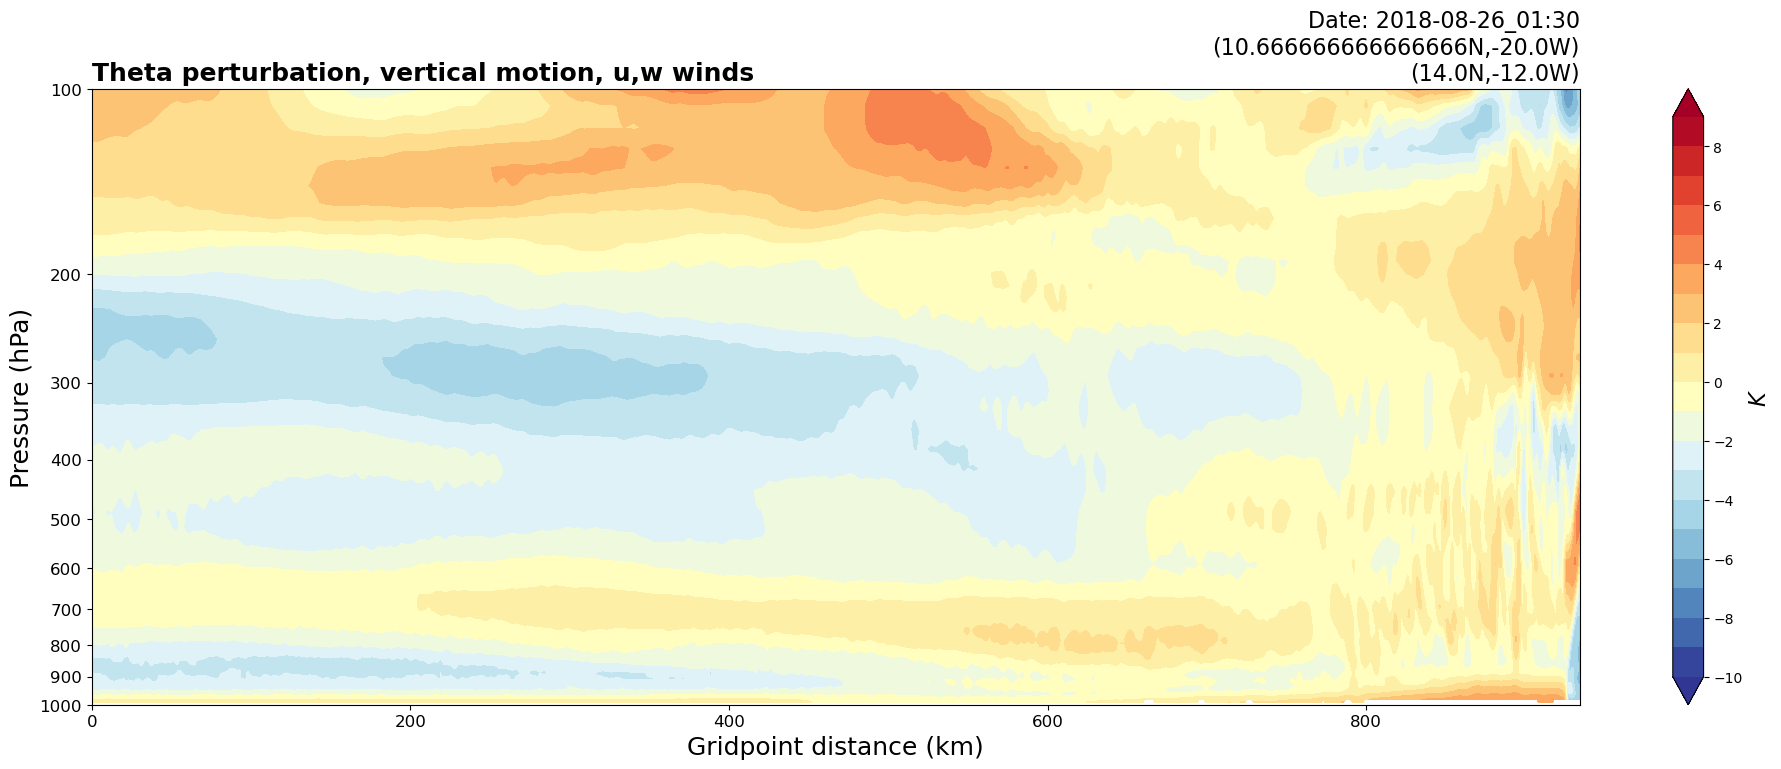

WRF valid time:  2018-08-26_02:00


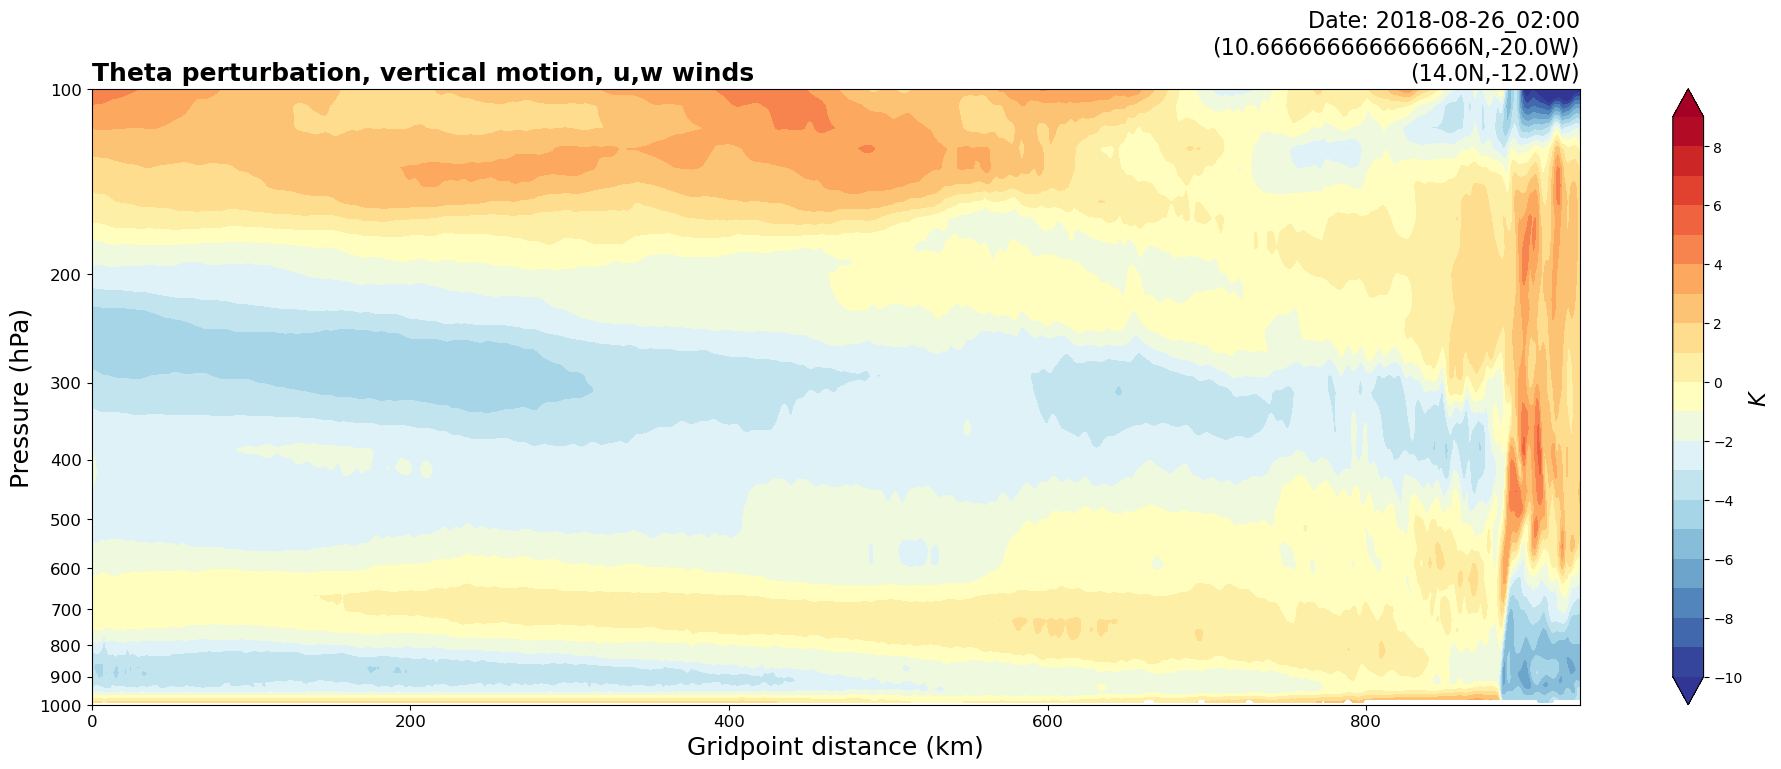

0
925
2.6647296
884
WRF valid time:  2018-08-26_02:30


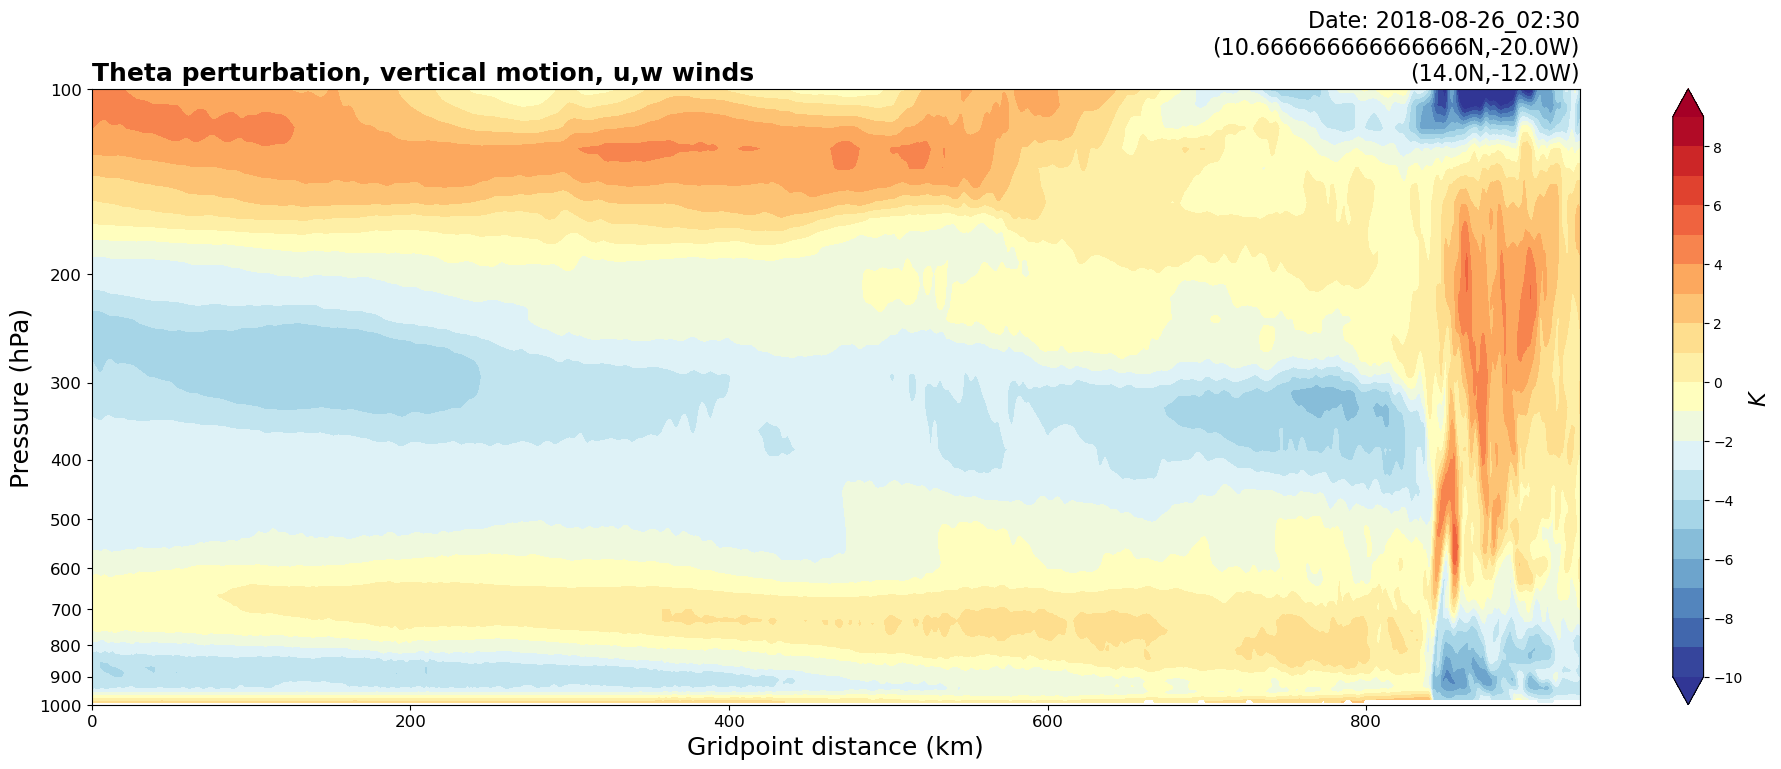

1
884
2.2536347
841
WRF valid time:  2018-08-26_03:00


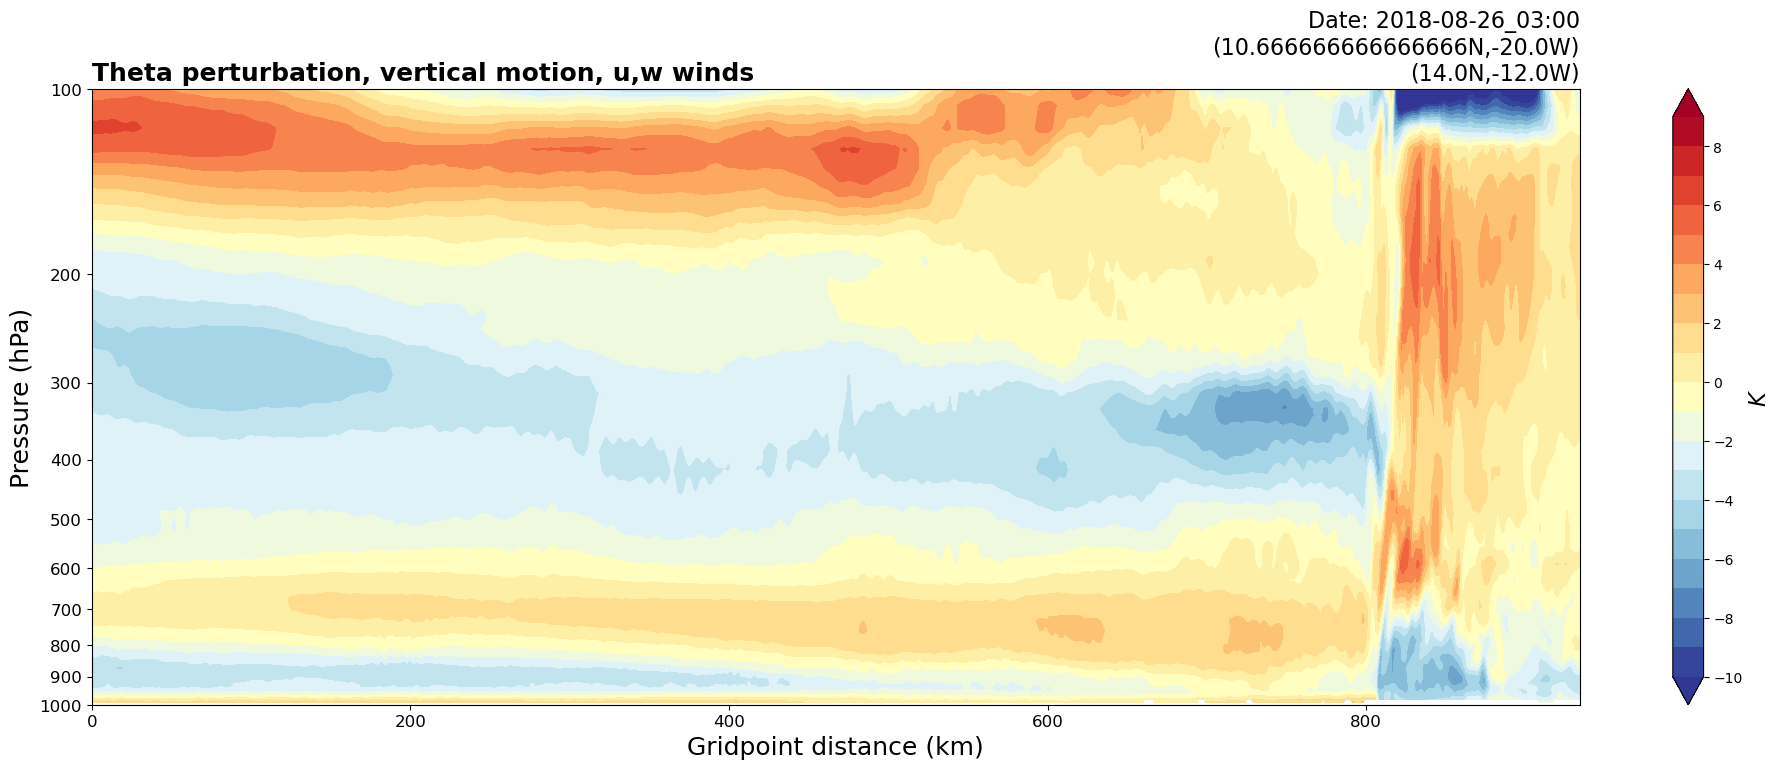

2
841
2.0190508
807
WRF valid time:  2018-08-26_03:30


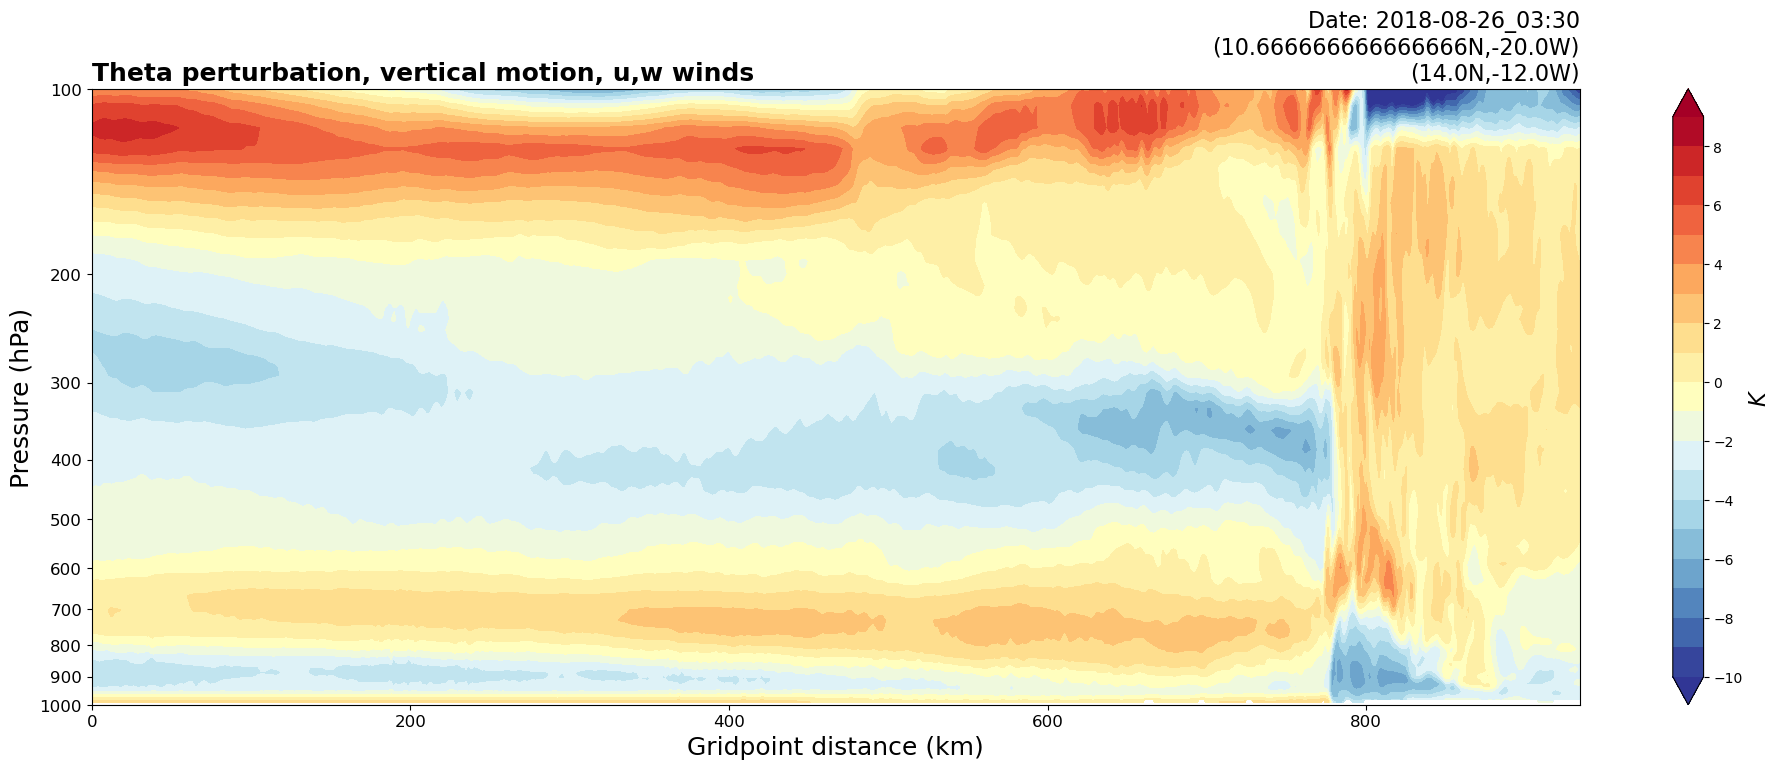

3
807
1.7695942
777
WRF valid time:  2018-08-26_04:00


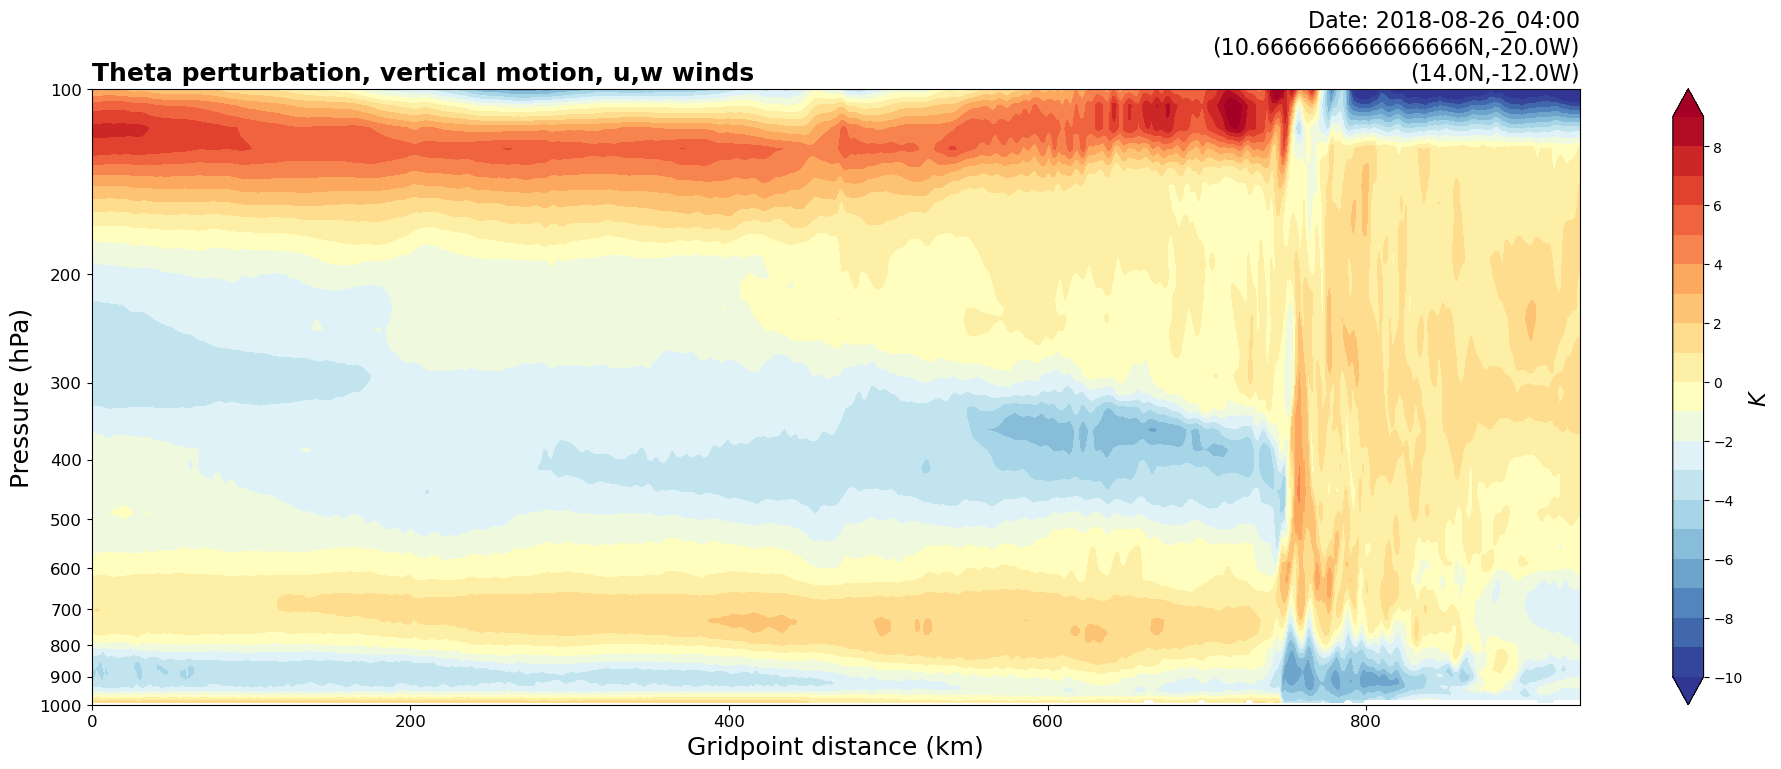

4
777
1.524152
746
WRF valid time:  2018-08-26_04:30


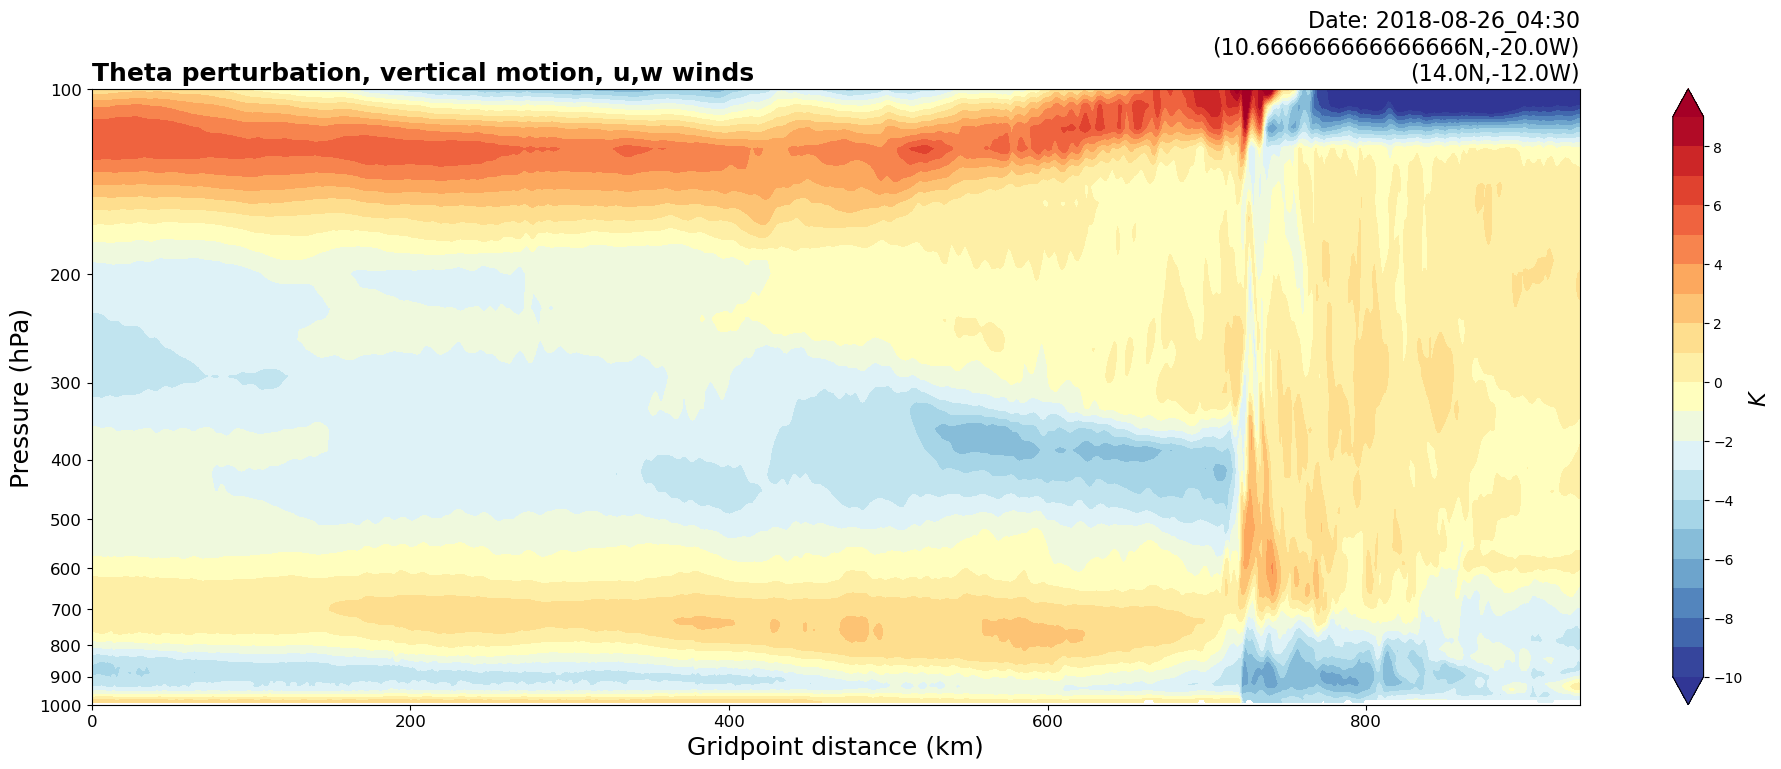

5
746
1.7293915
721
WRF valid time:  2018-08-26_05:00


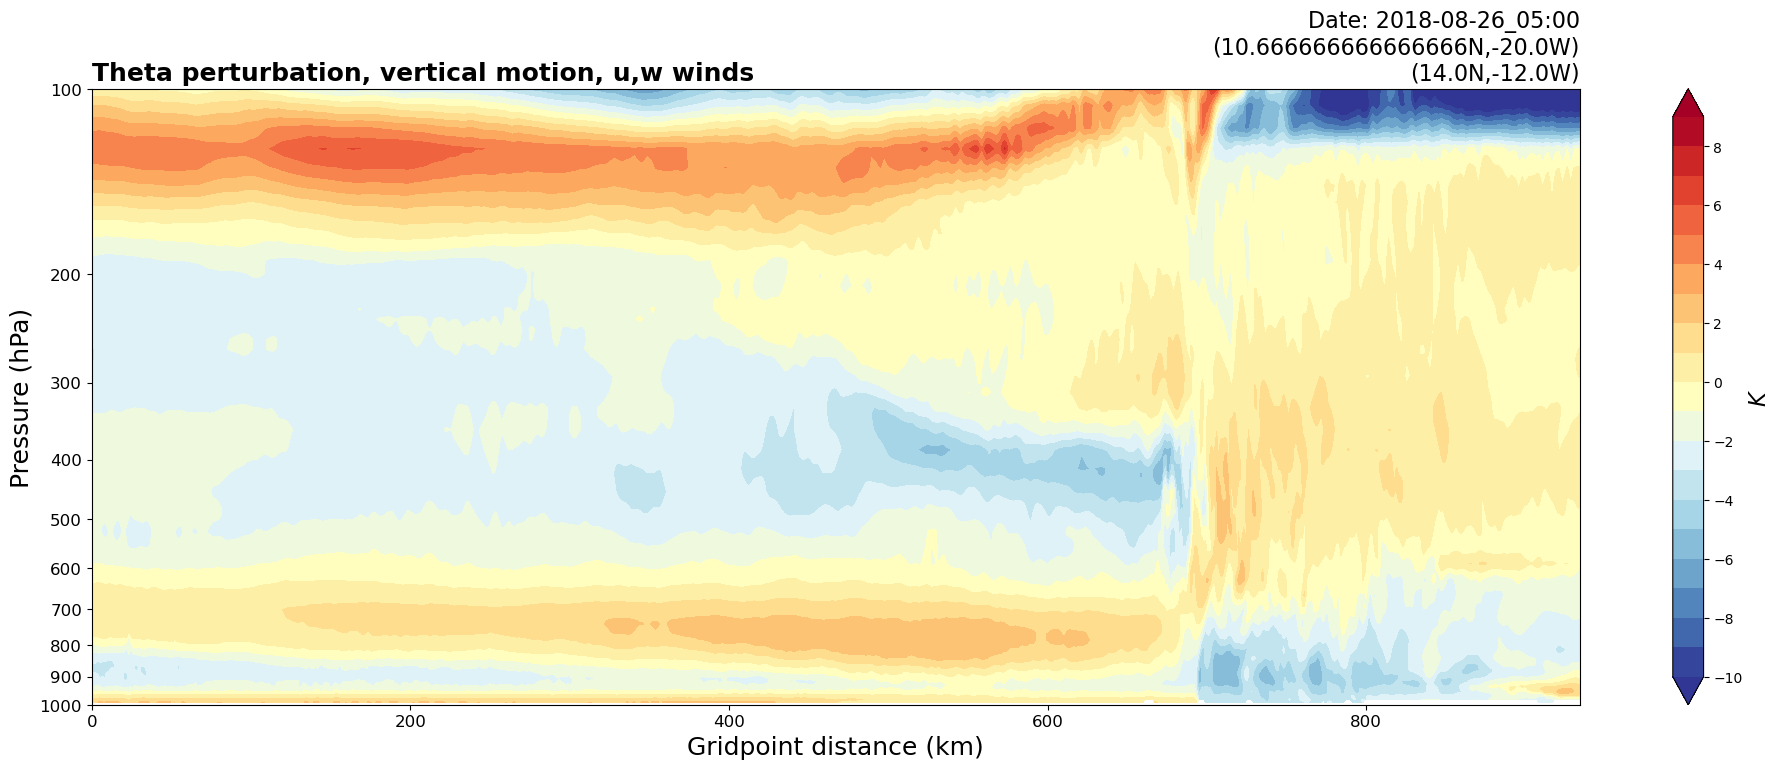

6
721
1.3445868
694
WRF valid time:  2018-08-26_05:30


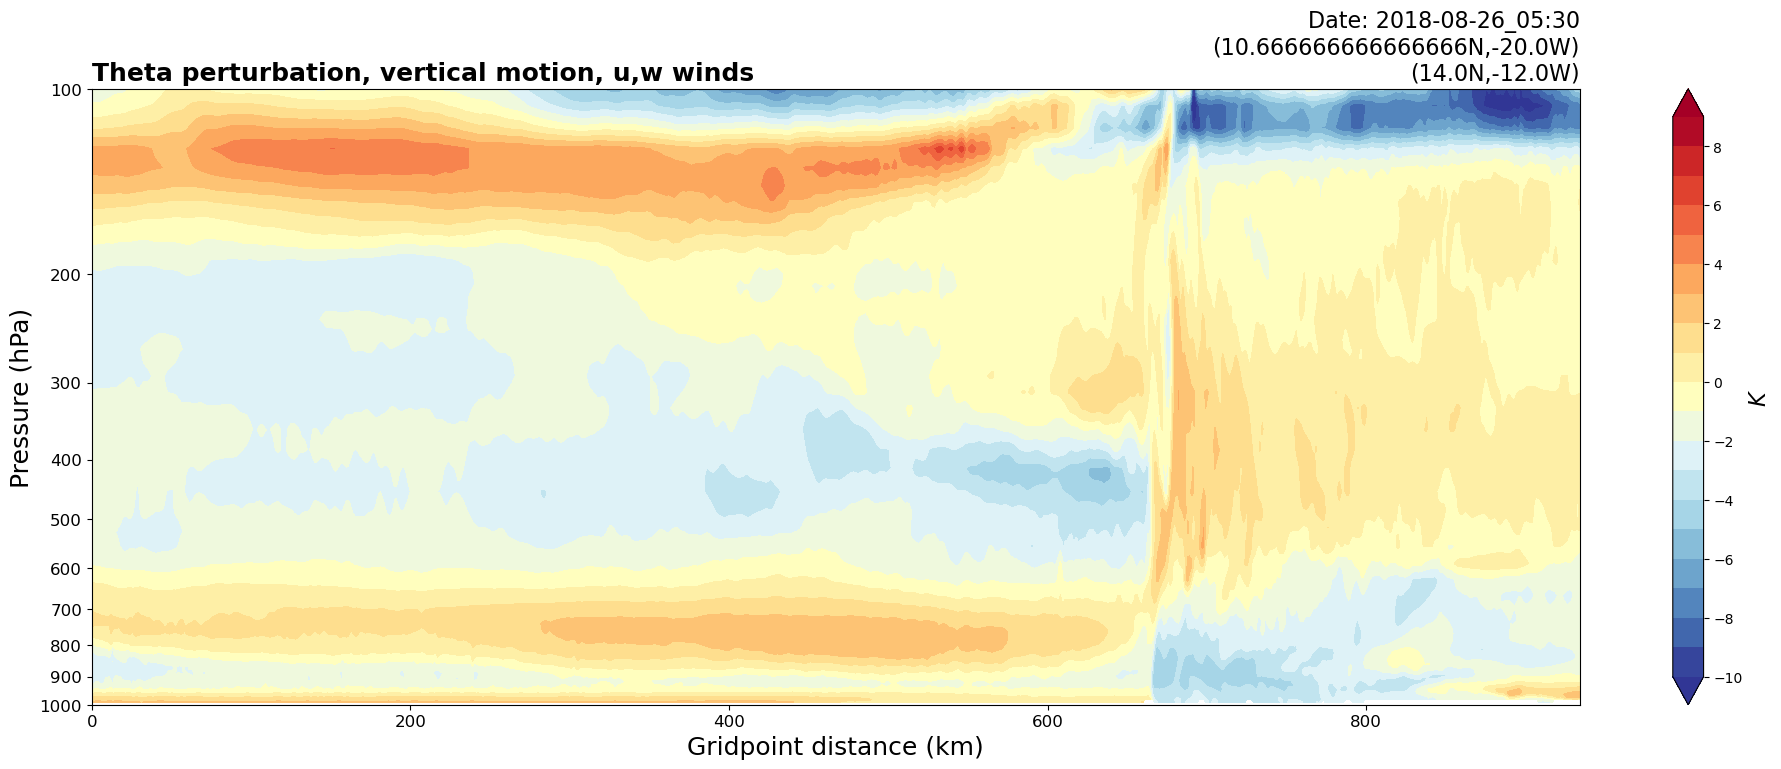

7
694
1.1968429
665
WRF valid time:  2018-08-26_06:00


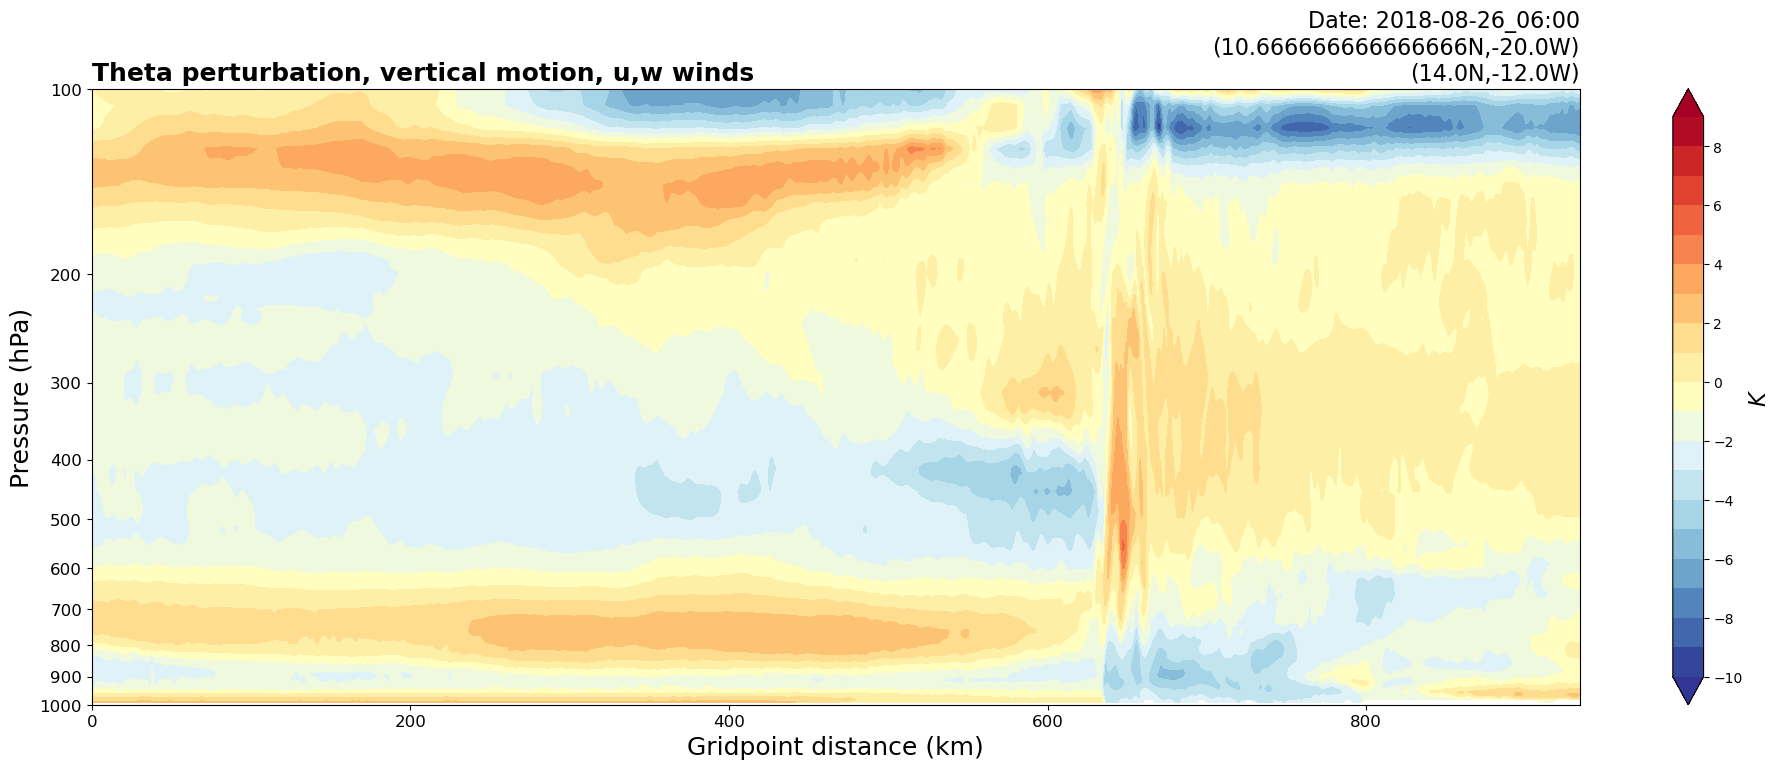

8
665
1.3806729
635
WRF valid time:  2018-08-26_06:30


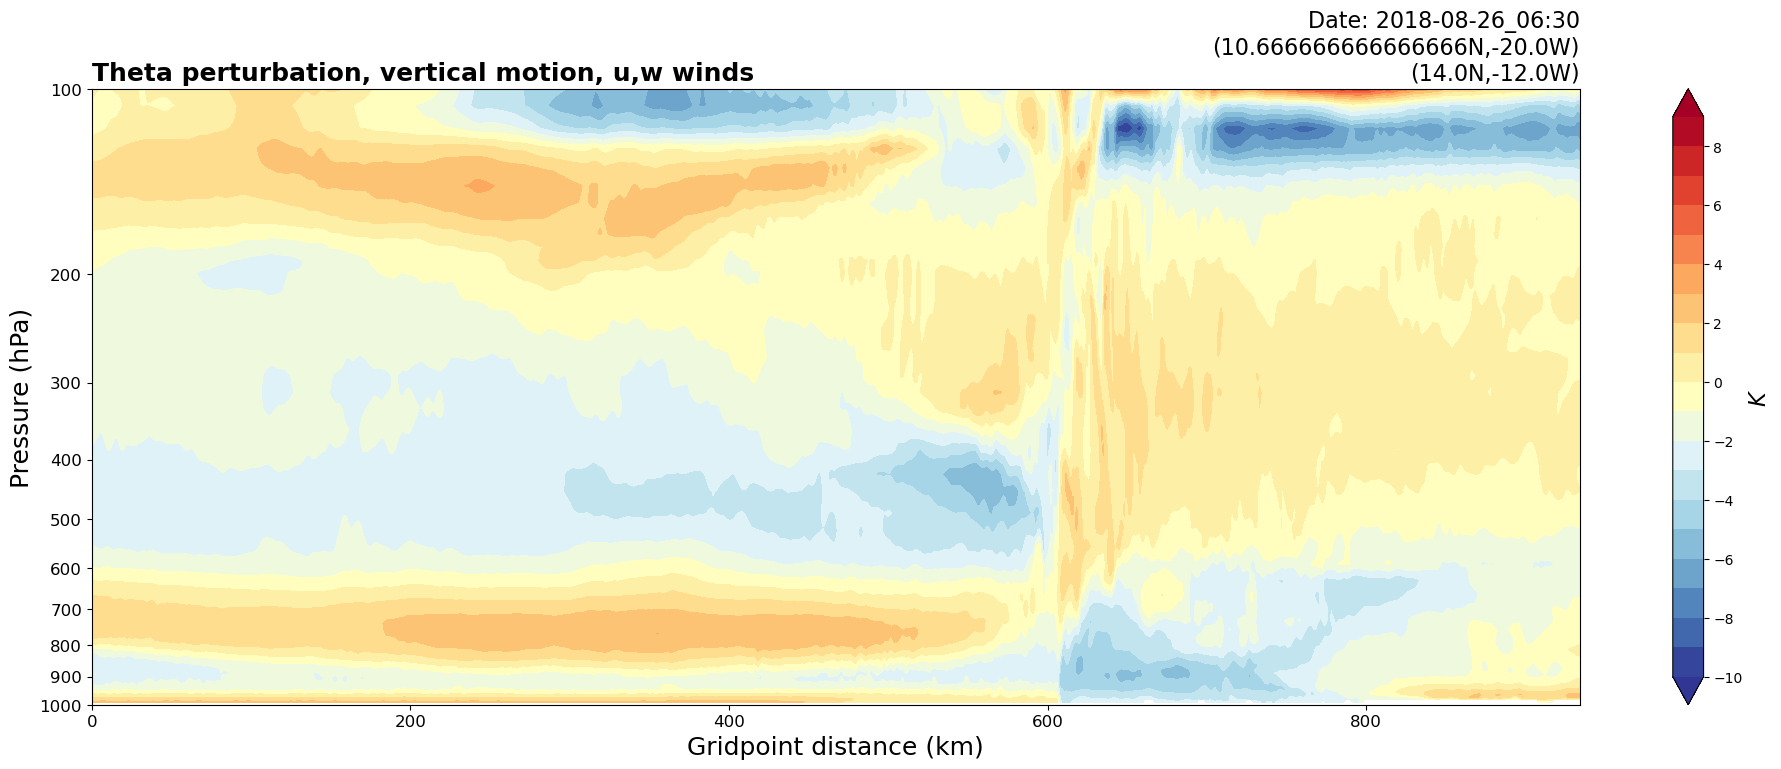

9
635
1.3172754
607
WRF valid time:  2018-08-26_07:00


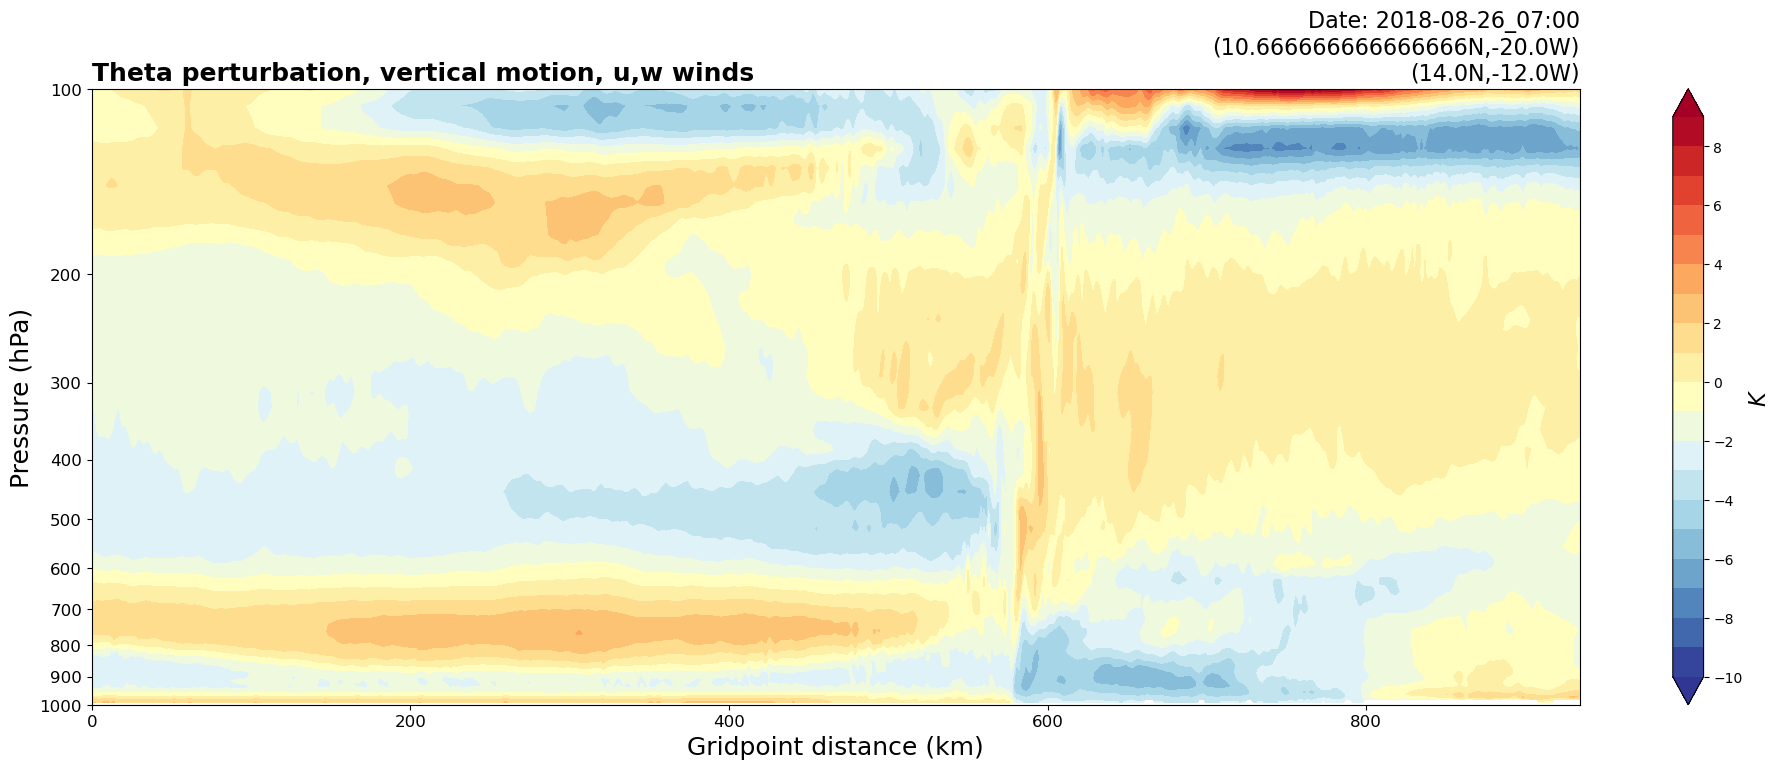

10
607
0.8683171
578
WRF valid time:  2018-08-26_07:30


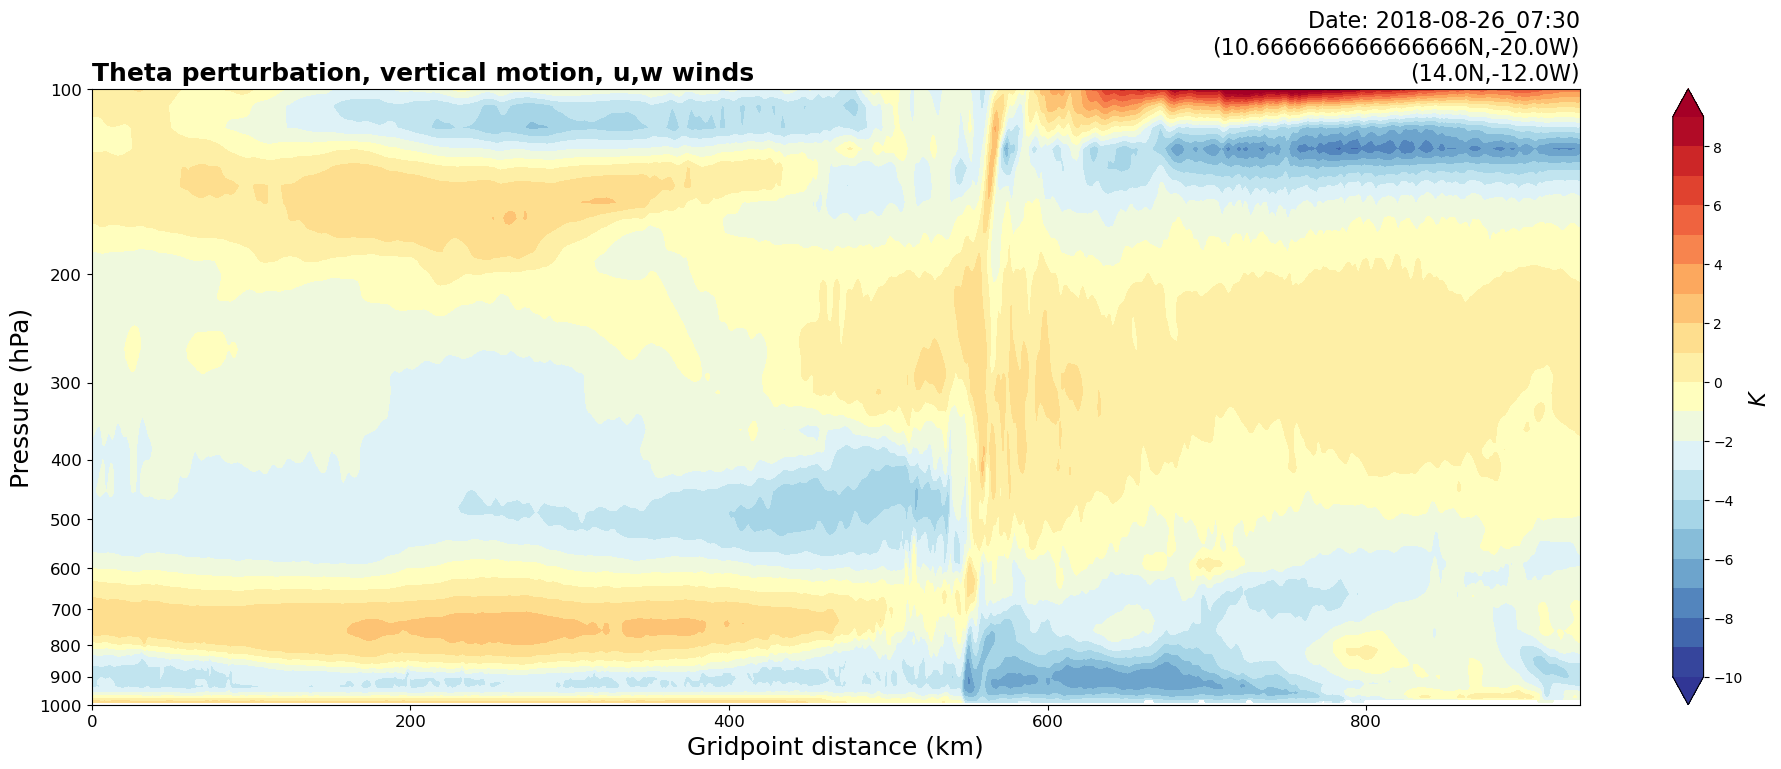

11
578
1.2597803
547
WRF valid time:  2018-08-26_08:00


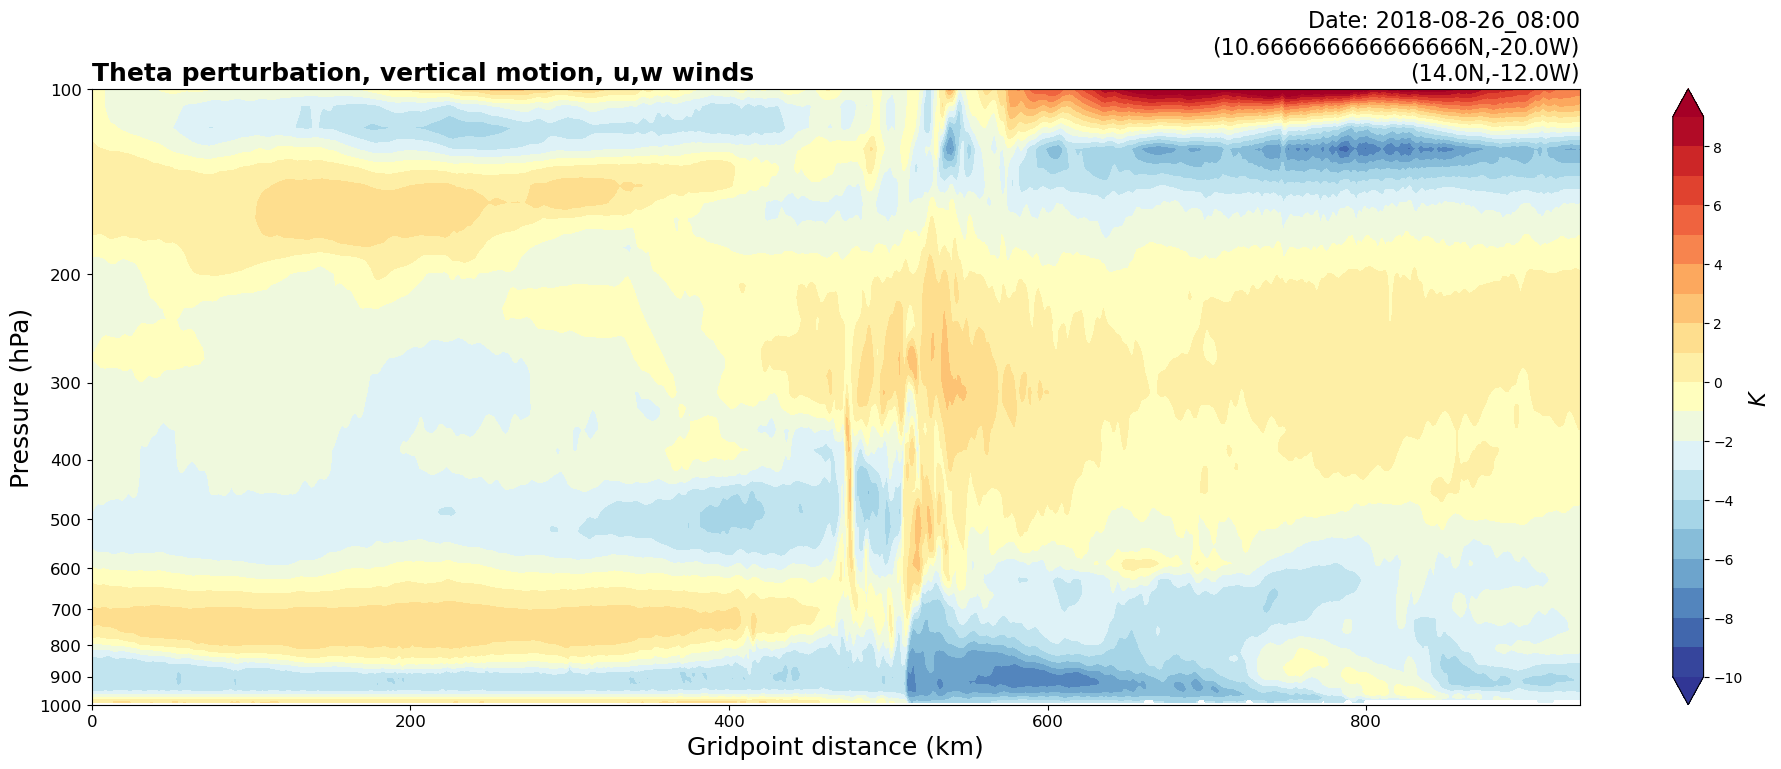

12
547
1.4657481
511
WRF valid time:  2018-08-26_08:30


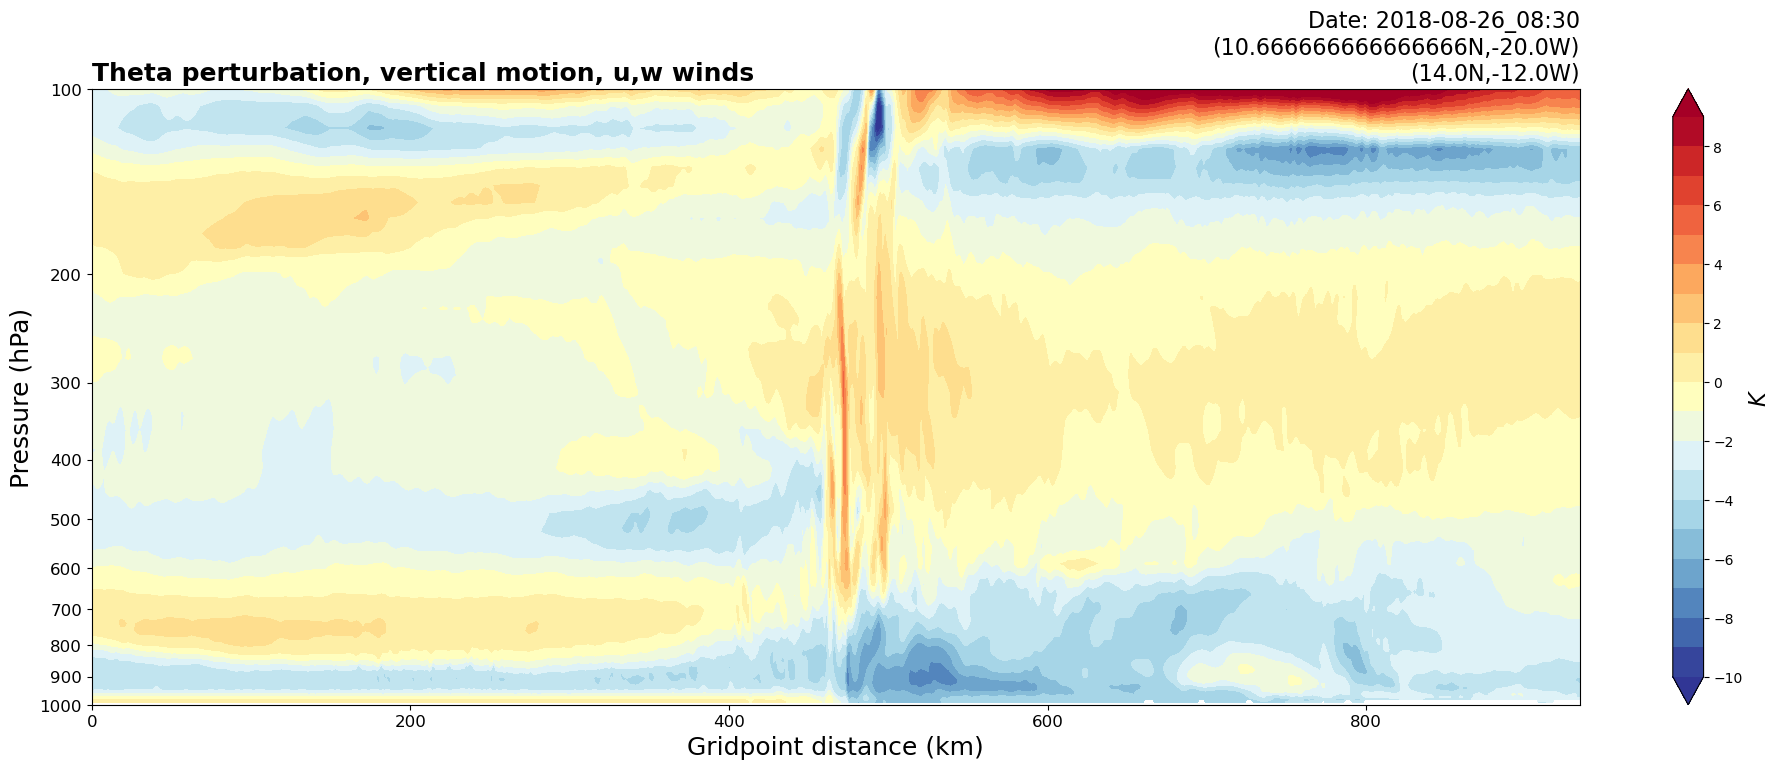

13
511
1.2266005
474
WRF valid time:  2018-08-26_09:00


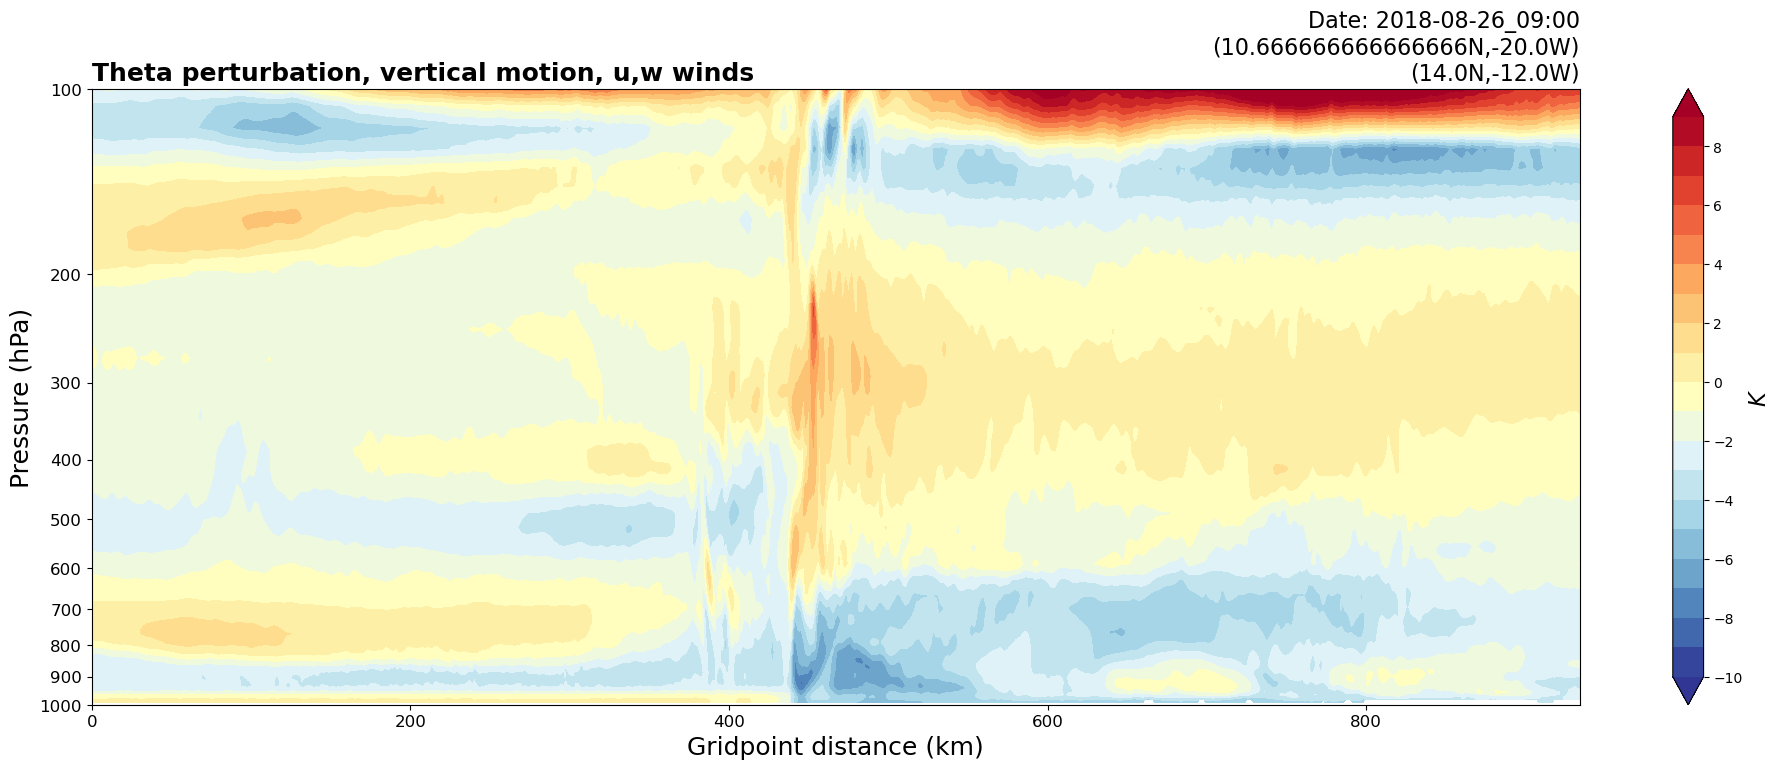

14
474
0.73558664
439
WRF valid time:  2018-08-26_09:30


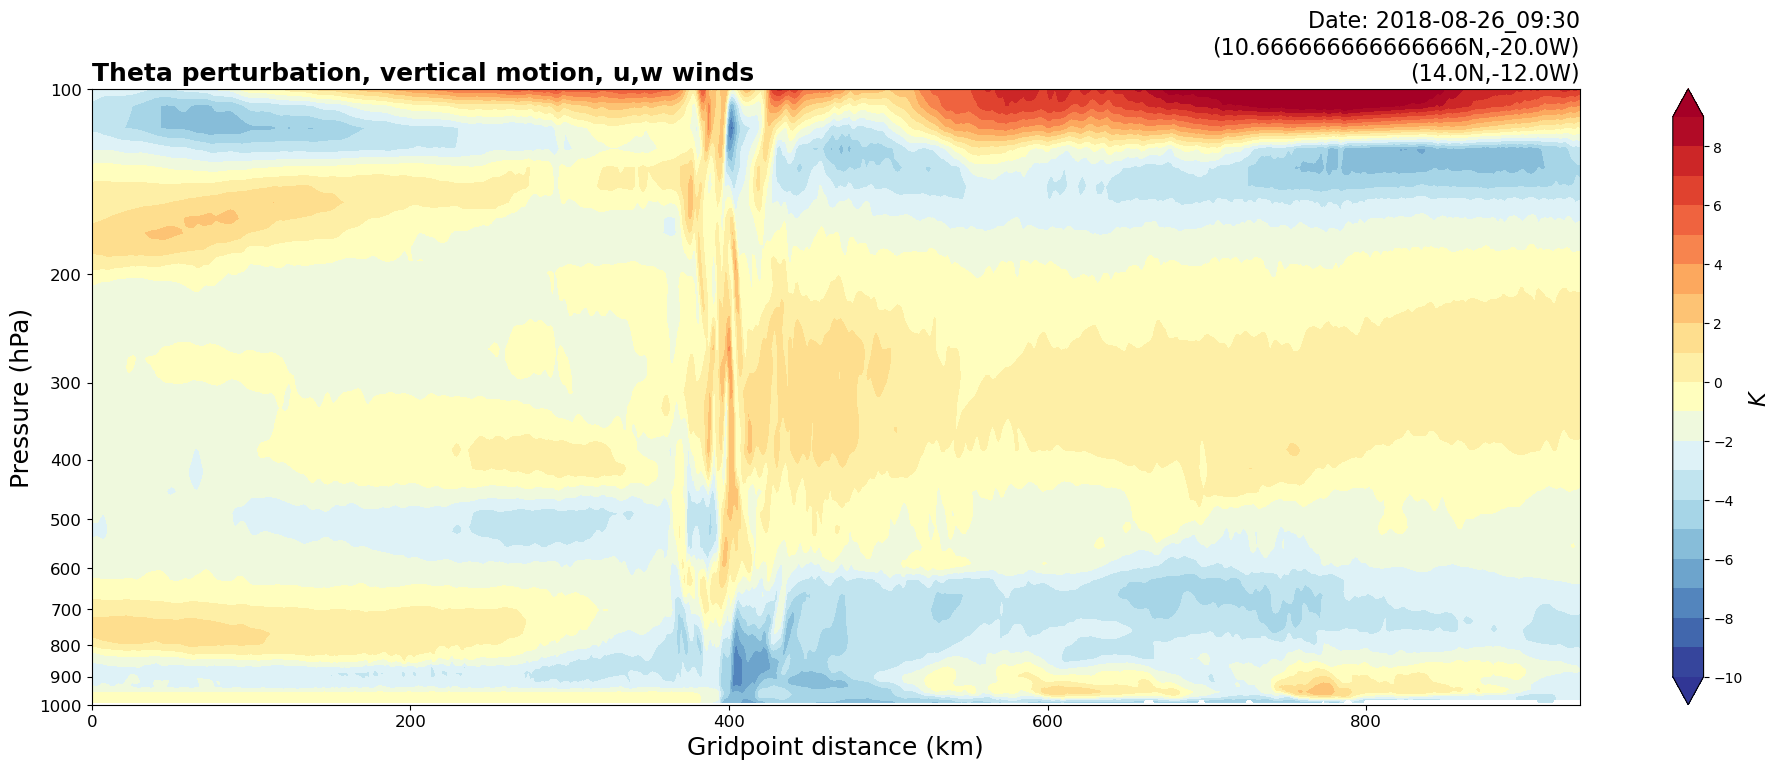

15
439
0.93939316
394
WRF valid time:  2018-08-26_10:00


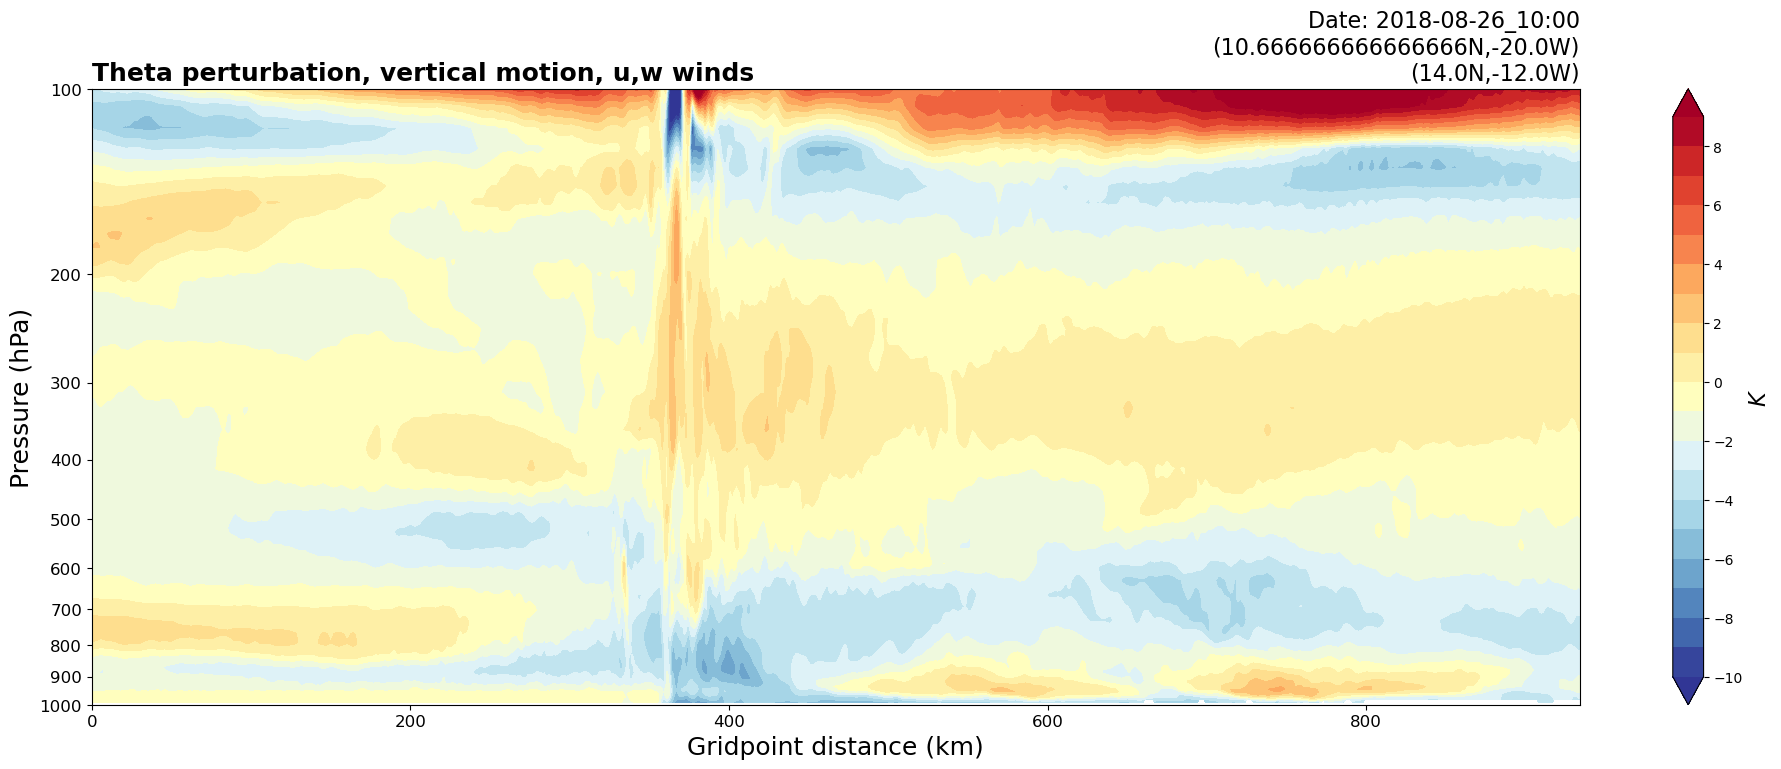

16
394
1.0129013
363
WRF valid time:  2018-08-26_10:30


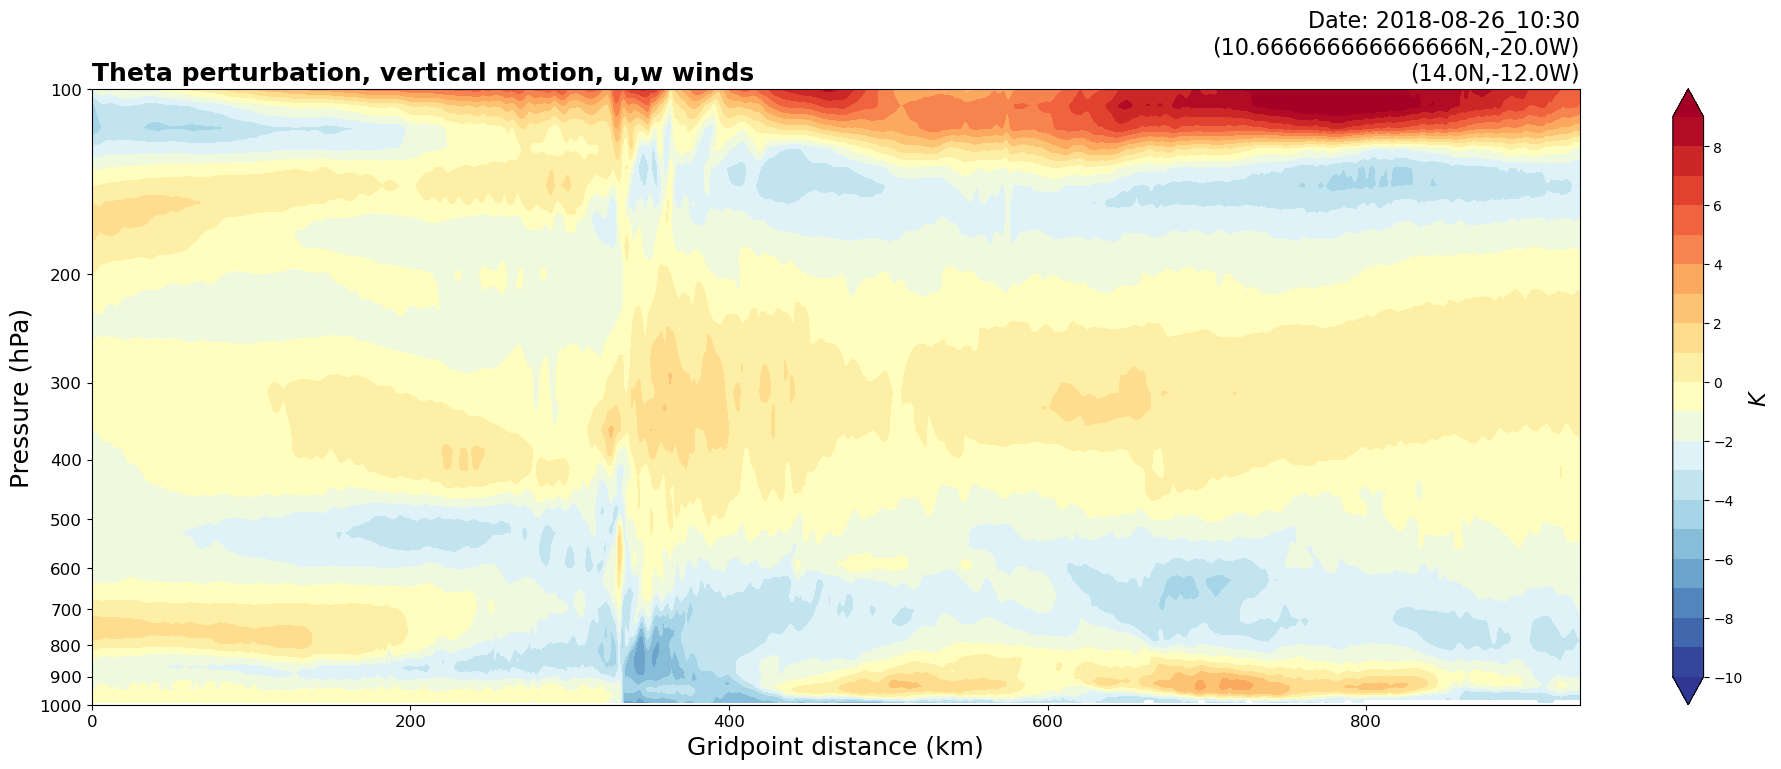

17
363
1.621927
333
WRF valid time:  2018-08-26_11:00


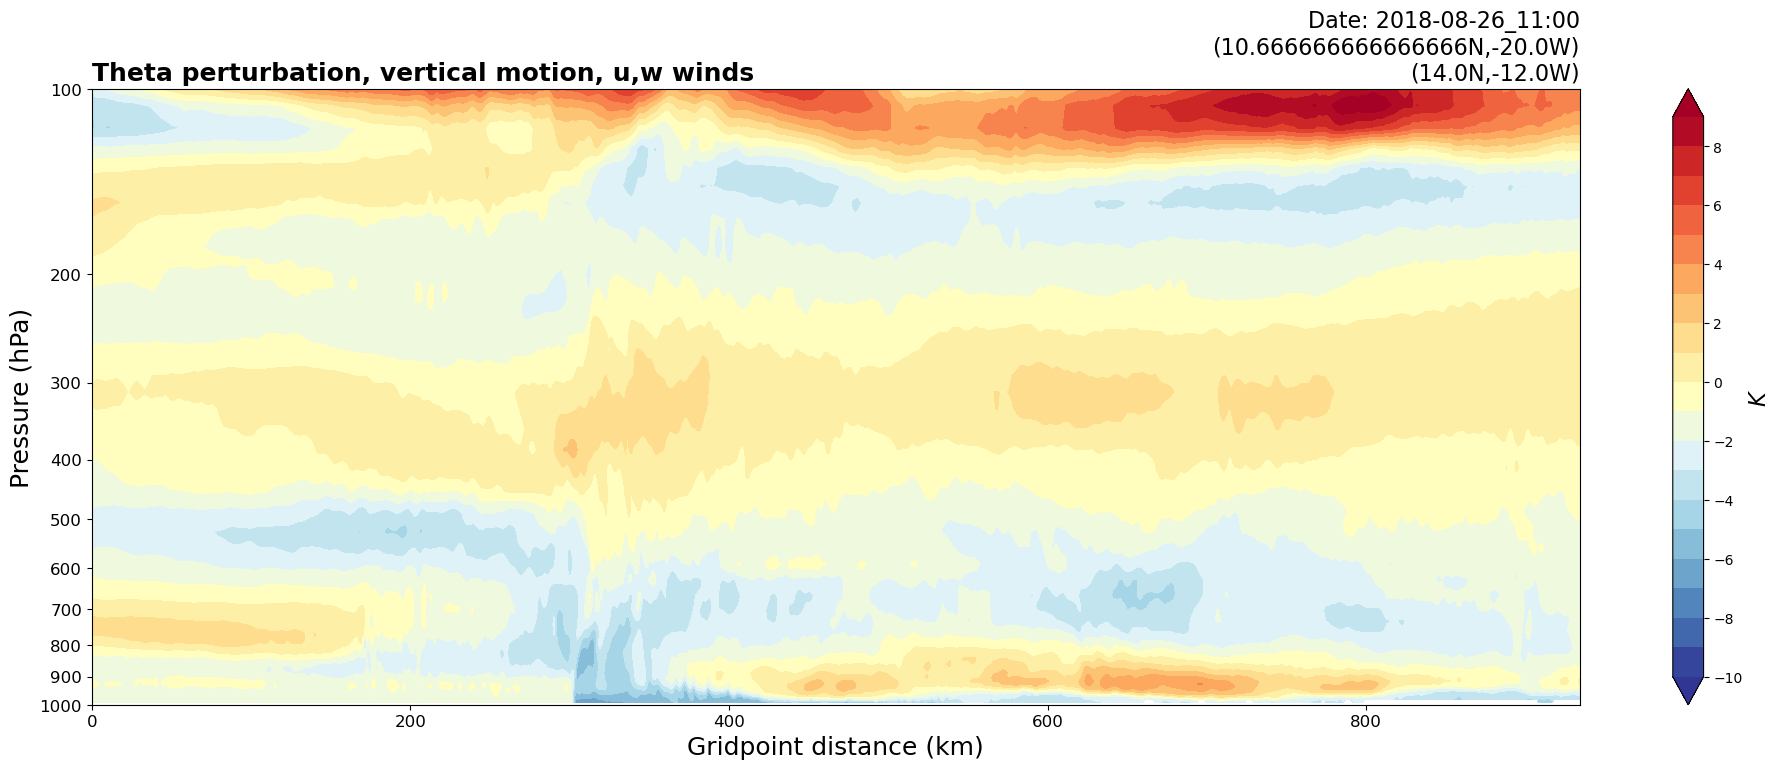

18
333
1.5121474
302
WRF valid time:  2018-08-26_11:30


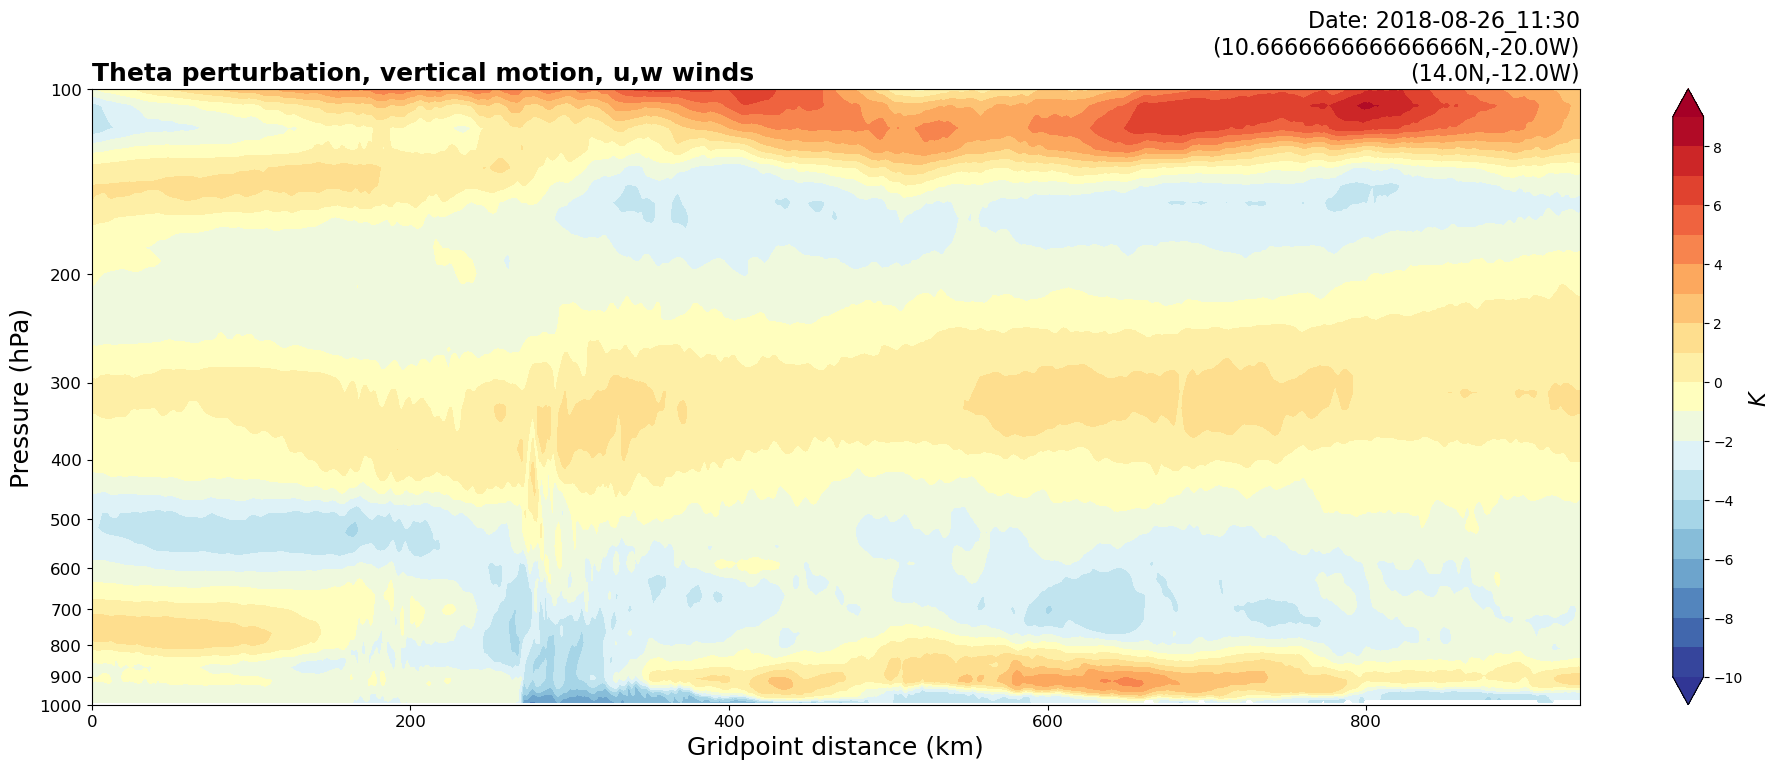

19
302
1.393576
270
WRF valid time:  2018-08-26_12:00


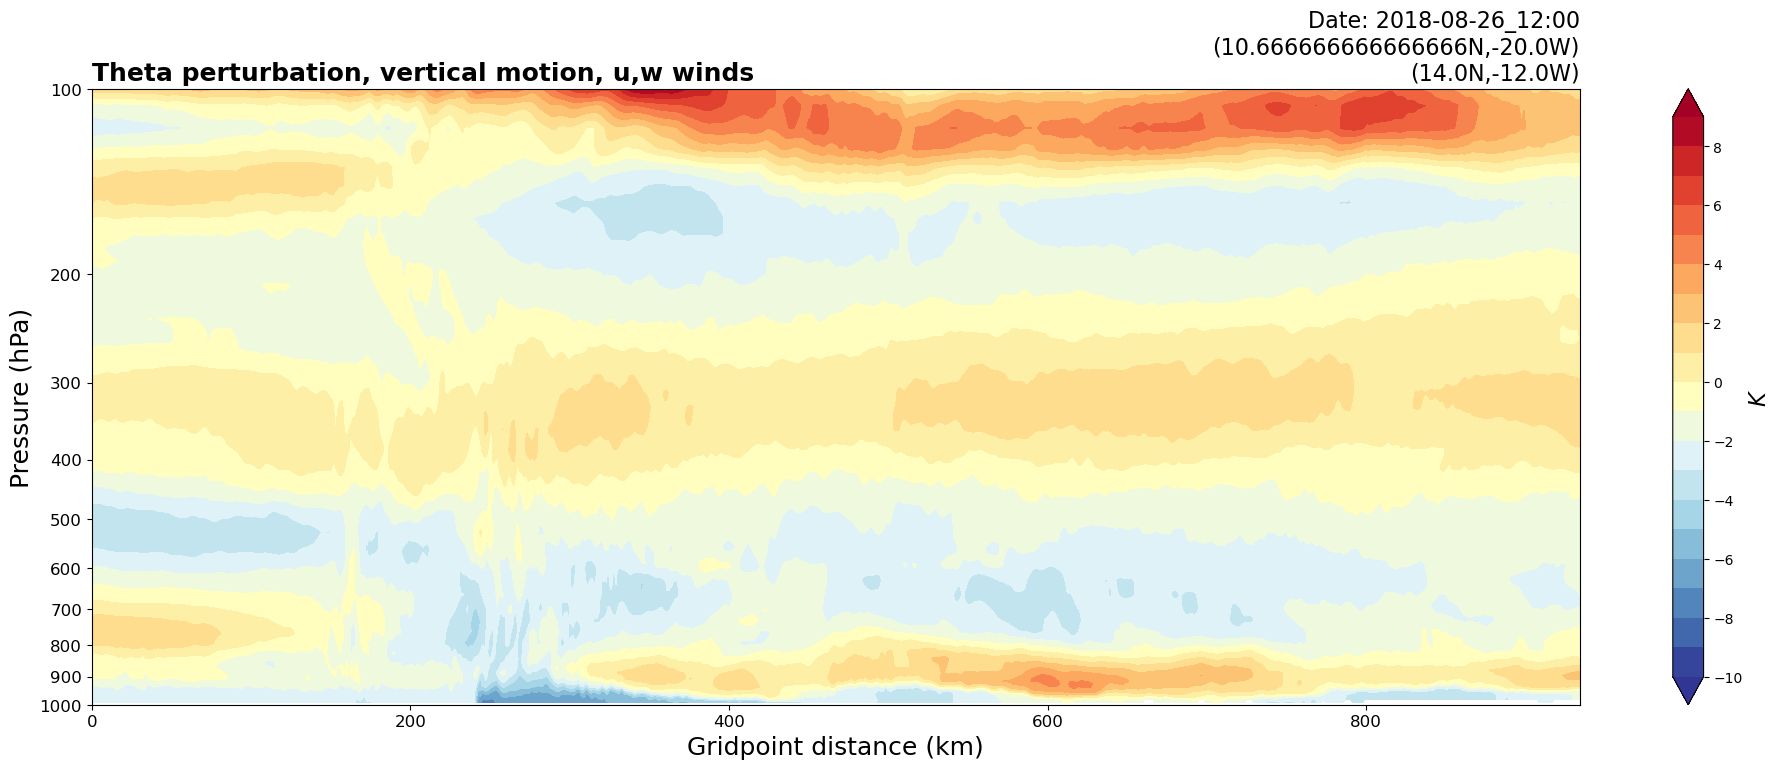

20
270
1.2866856
241
WRF valid time:  2018-08-26_12:30


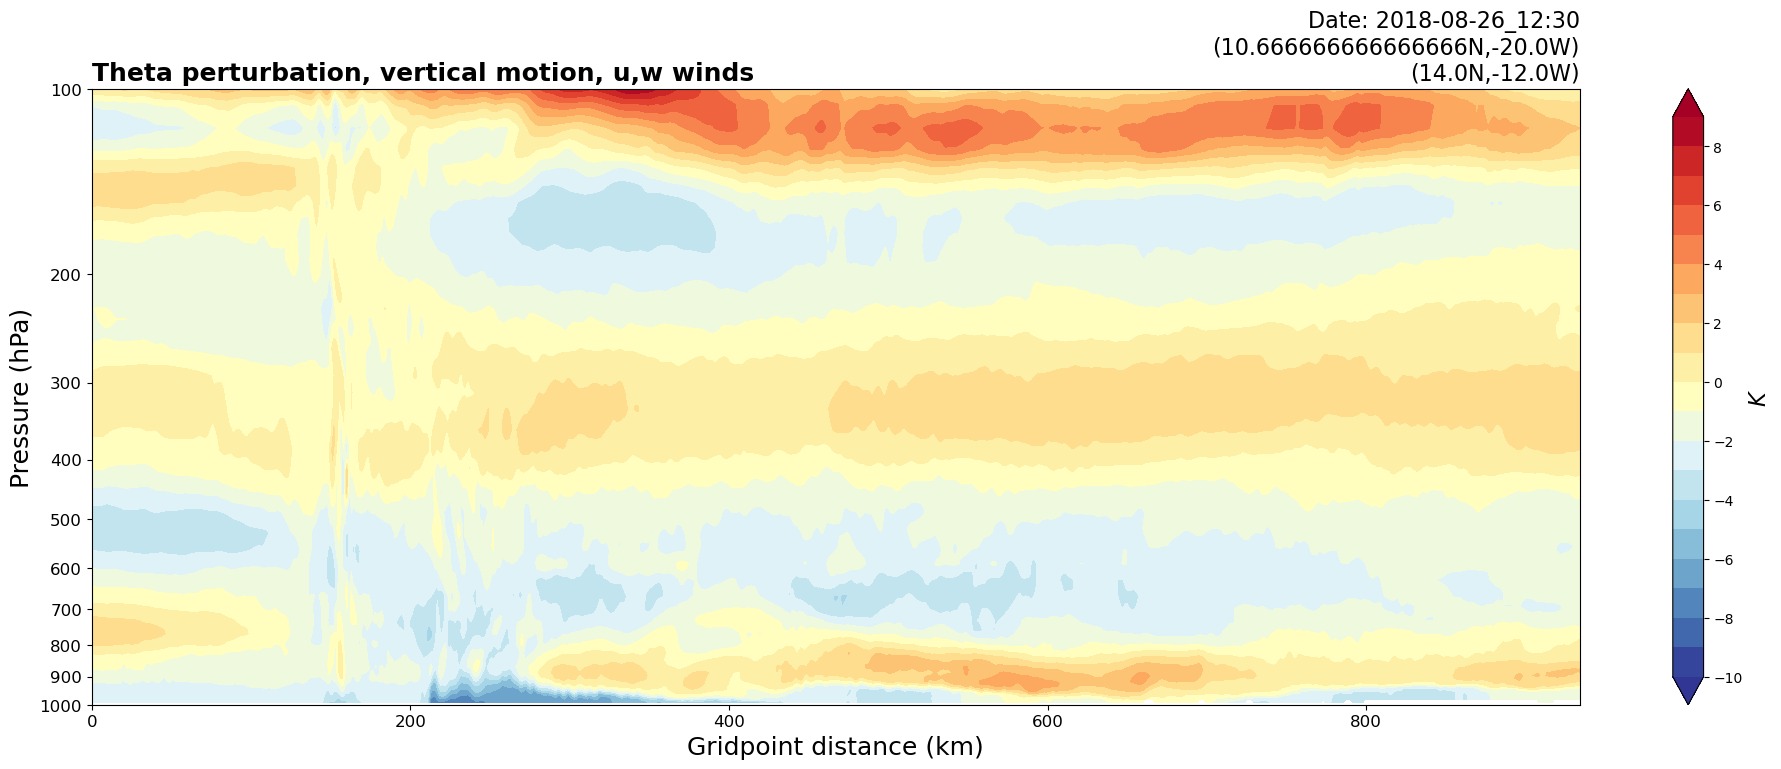

21
241
1.3765469
212
WRF valid time:  2018-08-26_13:00


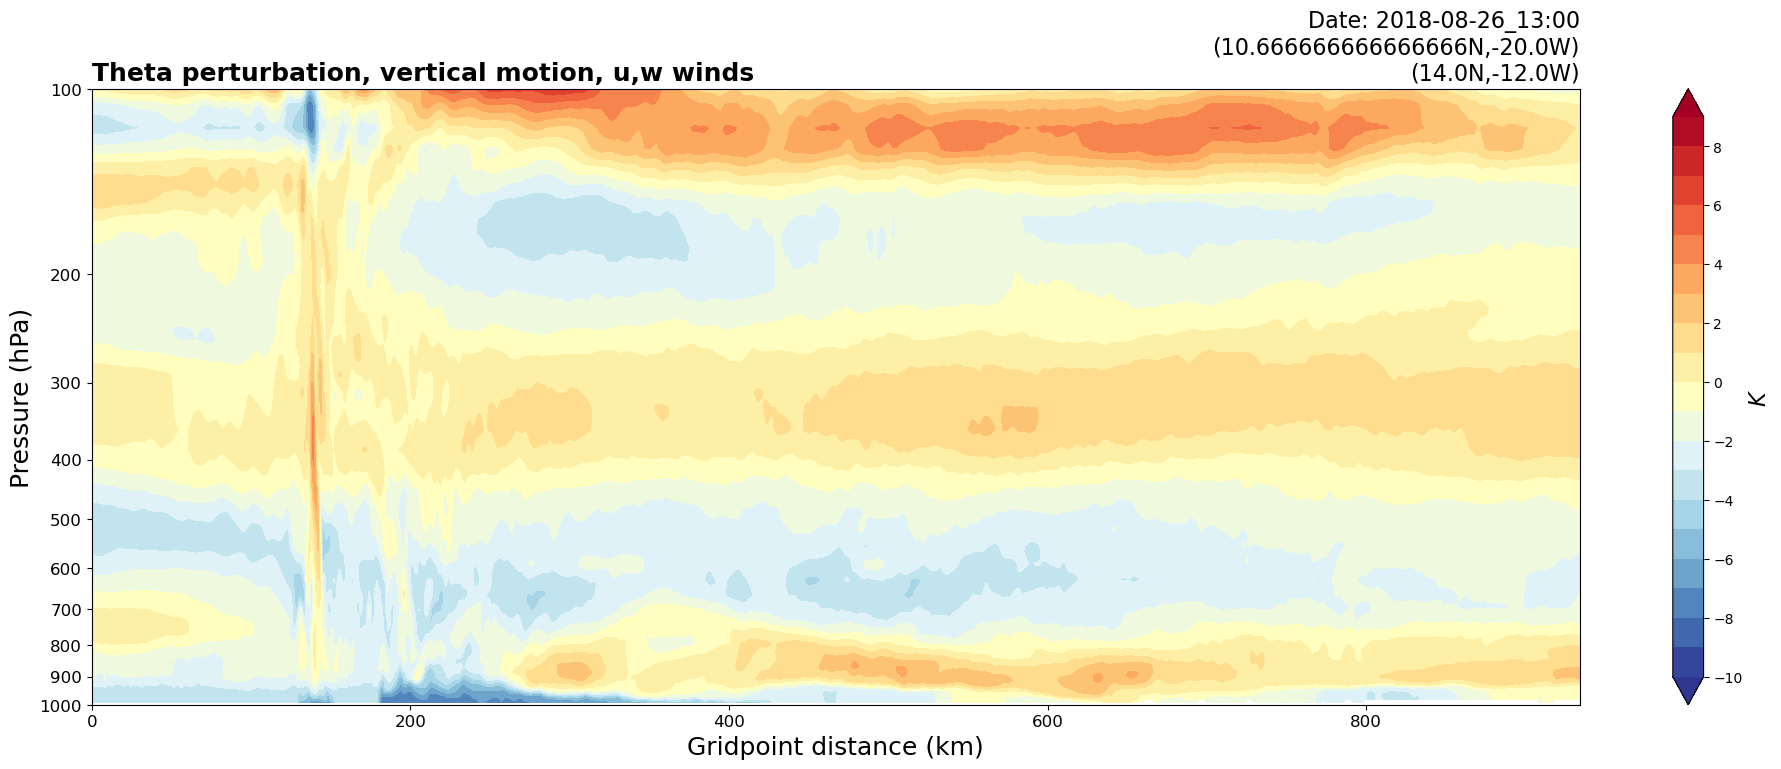

22
212
0.9816382
181
WRF valid time:  2018-08-26_13:30


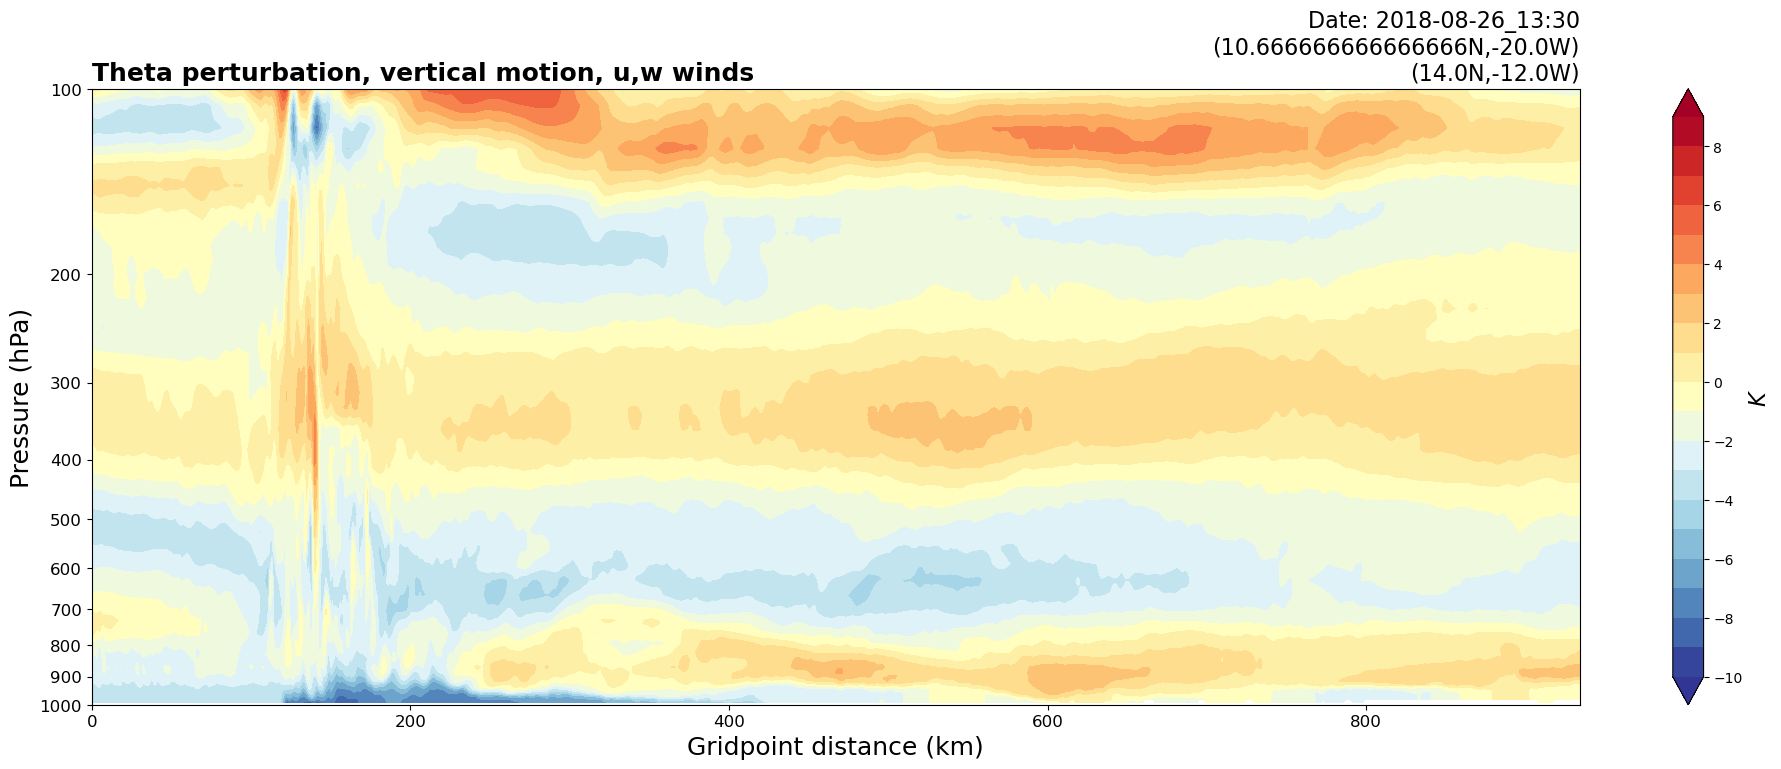

23
181
0.6019857
136
WRF valid time:  2018-08-26_14:00


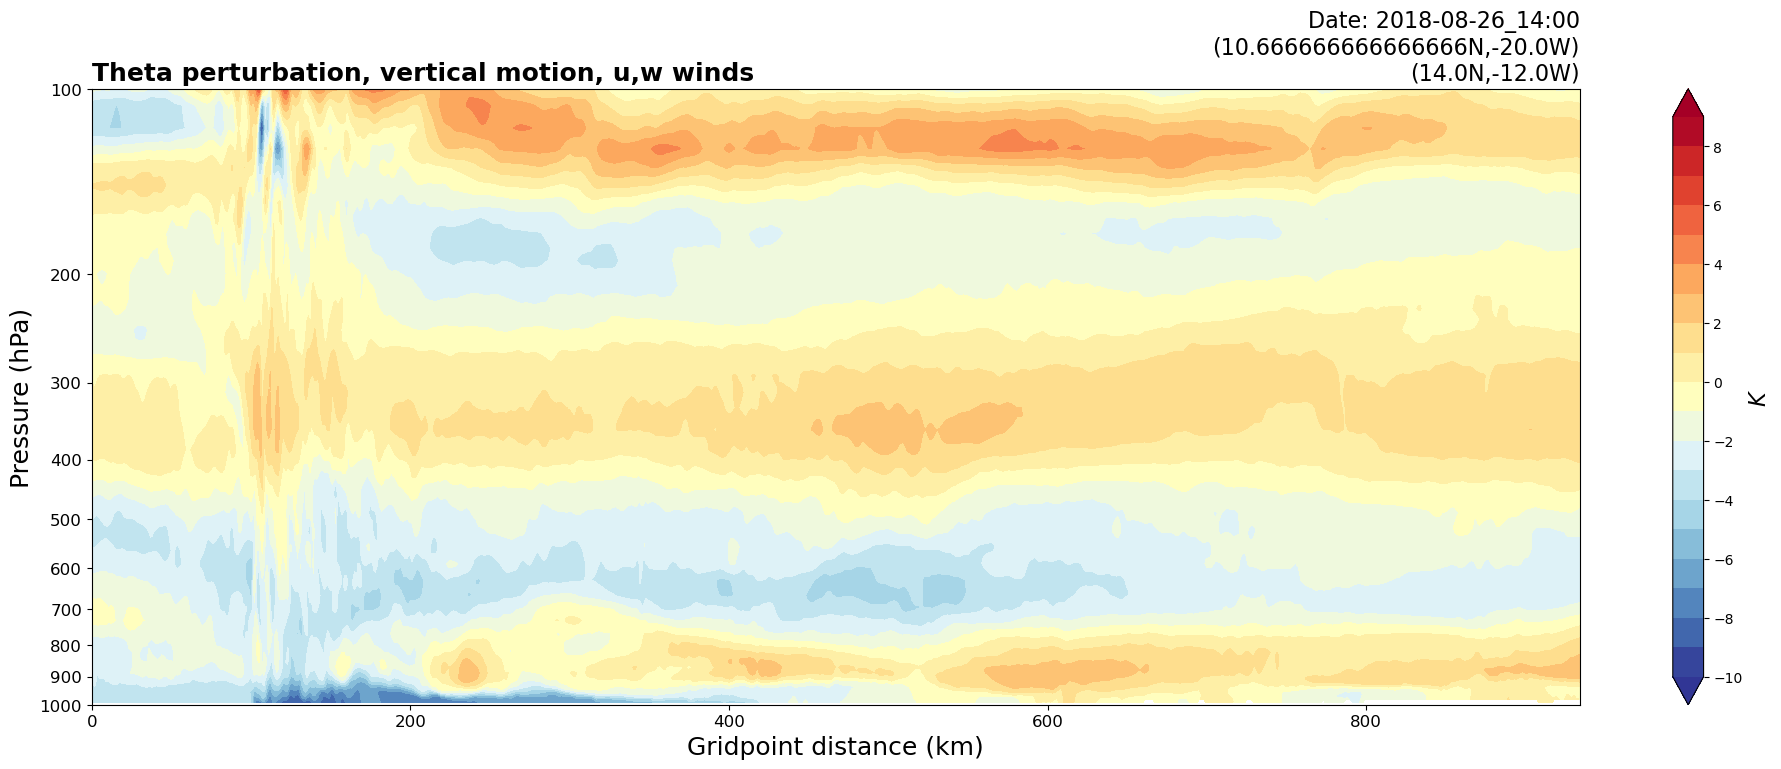

24
136
0.7924644
101
WRF valid time:  2018-08-26_14:30


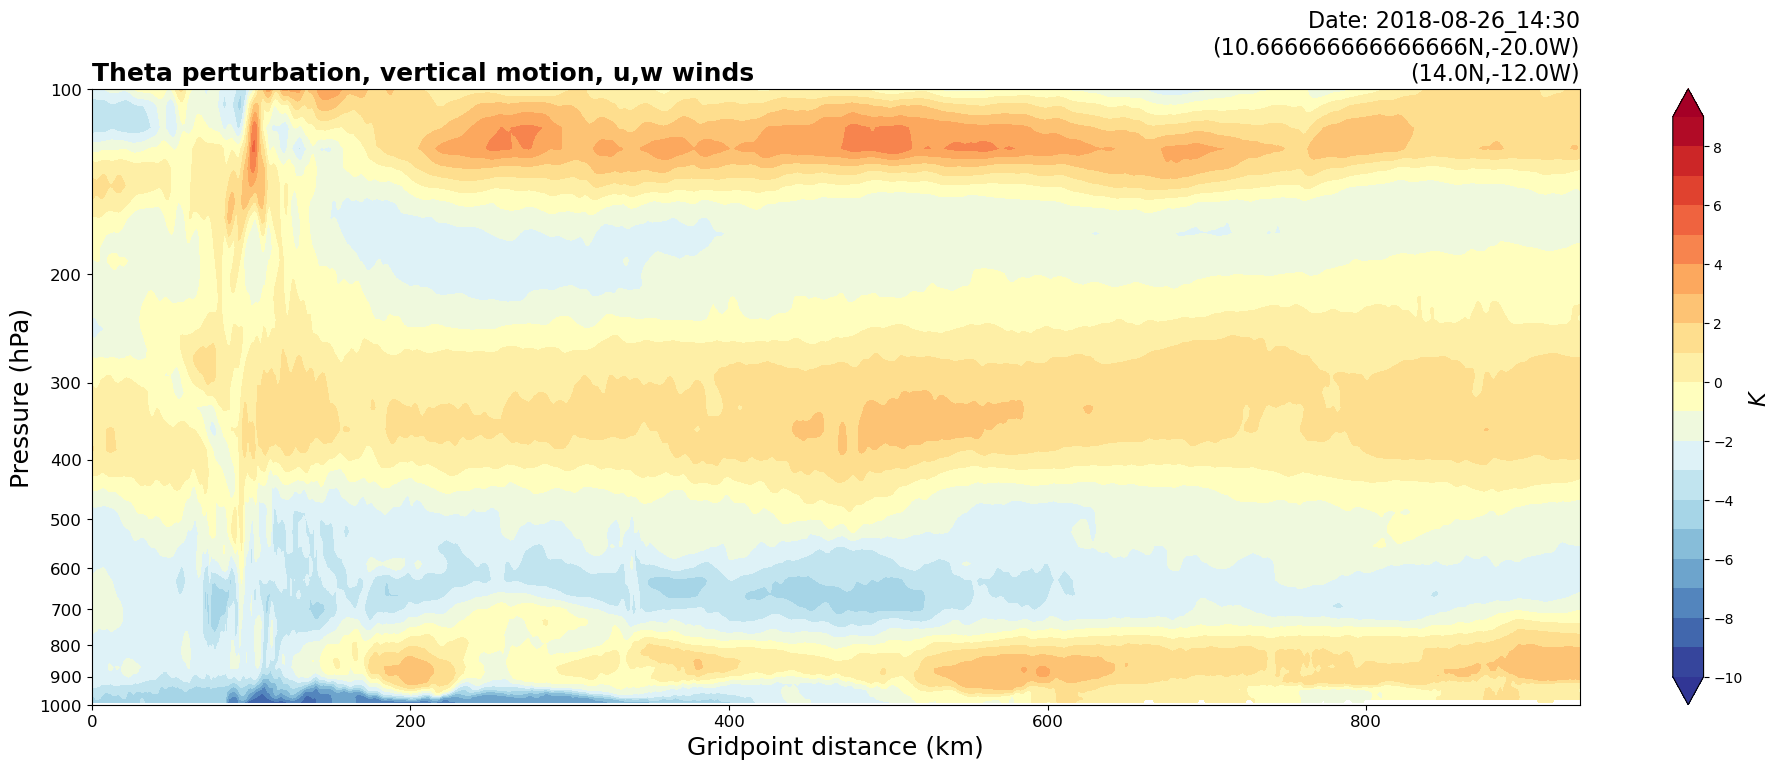

25
101
0.7236898
85
WRF valid time:  2018-08-26_15:00


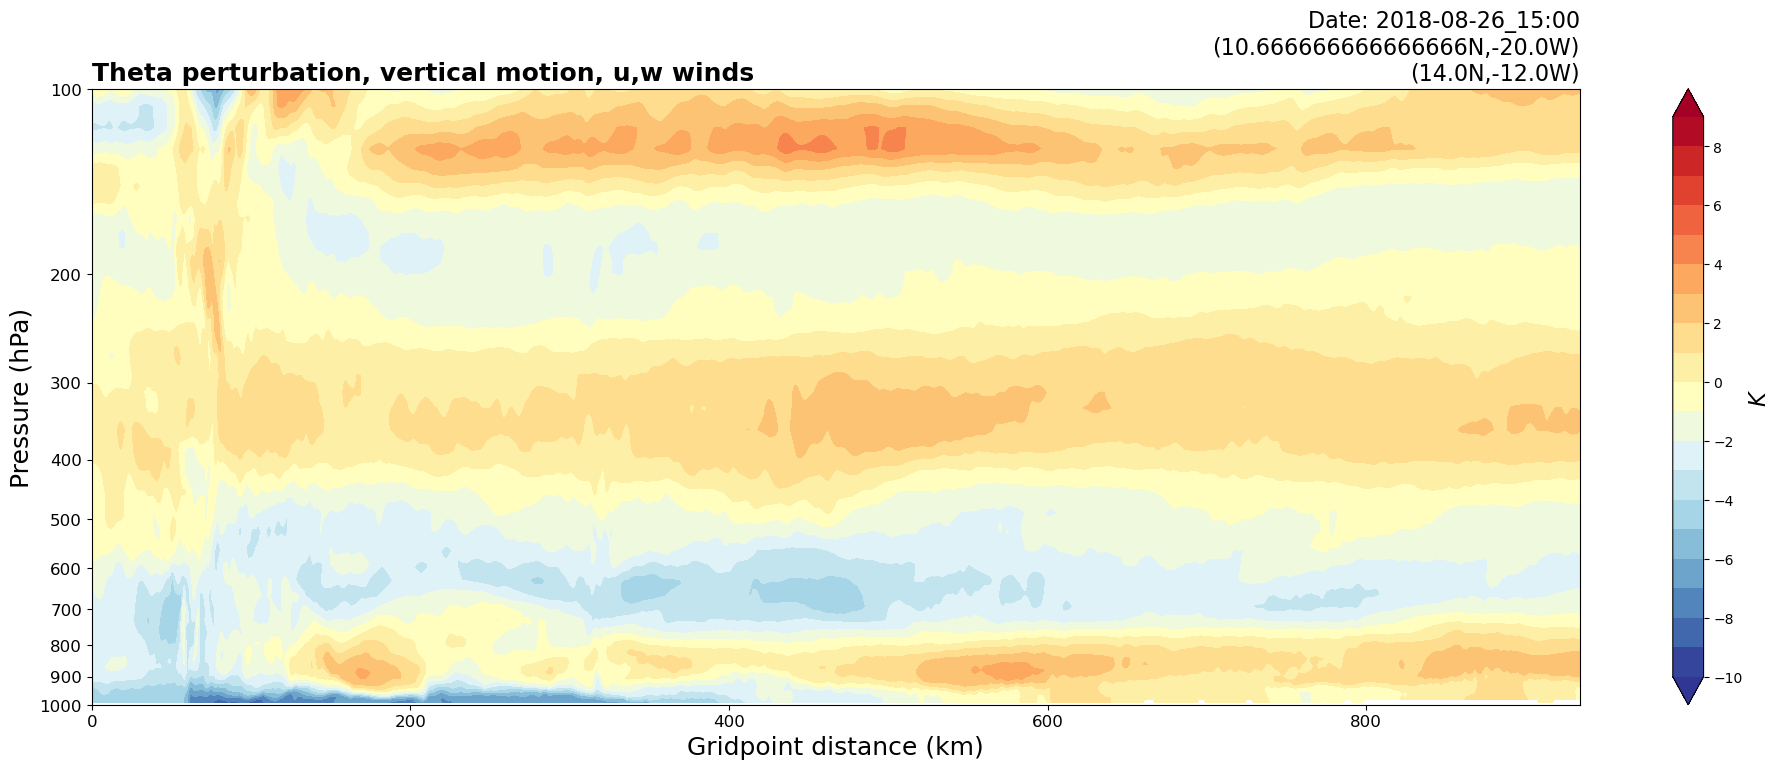

26
85
0.706069
61
WRF valid time:  2018-08-26_15:30


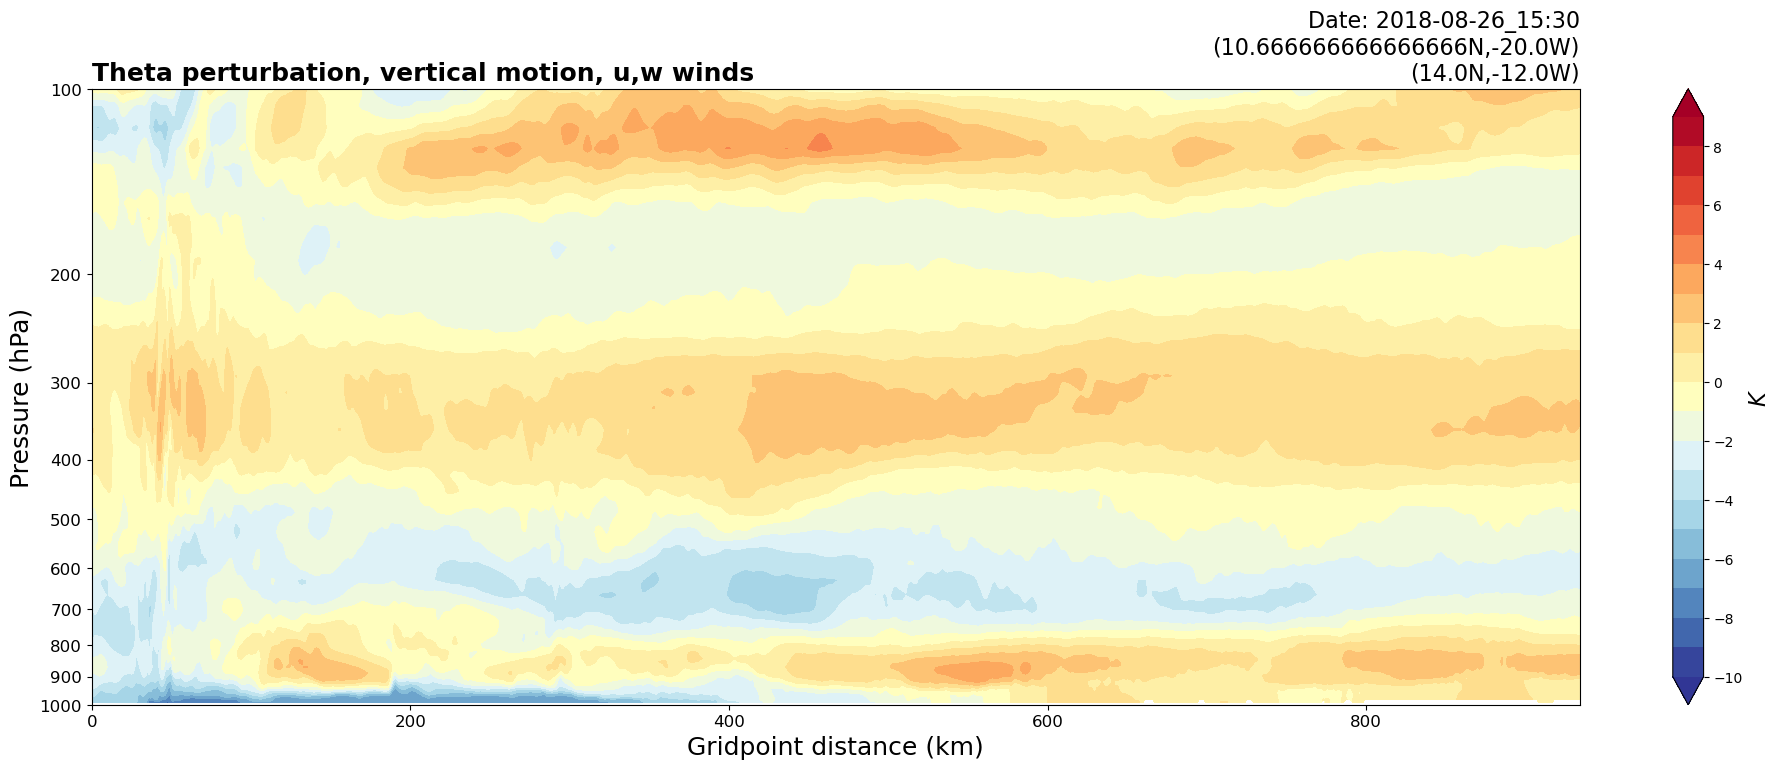

27
61


In [25]:
max_list_idx = []
for i in range(39,70):  # for north
    # Create an aerial abmient theta box ahead of the cross section
    try:
        ### For northern MCS
        lat_max2 = lat_max + 0.5  # expand lat cross section box 0.5 degrees south and north
        lat_min2 = lat_min - 0.5
        lon_max2 = lon_max  + (i-38)/3  
        lon_min2 = lon_max2 - 1.5  
        
        idx = np.where(lat <= lat_min2)
        min_lat_idx_50 = idx[0][-1]
        idx = np.where(lat <= lat_max2)
        max_lat_idx_50 = idx[0][-1]
        
        idx = np.where(lon <= lon_min2)
        min_lon_idx_50 = idx[0][-1]
        idx = np.where(lon <= lon_max2)
        max_lon_idx_50 = idx[0][-1]
        
        wrf_out_data = xr.open_dataset(datafiles[i])
        ncfile = Dataset(datafiles[i])
        Time=wrf.extract_times(ncfile, timeidx=0, method='cat', squeeze=True, cache=None, meta=False, do_xtime=False)
        timestr=(str(Time))
        # Set up one time string for plot titles, another for file names
        titletime=(timestr[0:10]+' '+timestr[11:16])
        filetime=(timestr[0:10]+'_'+timestr[11:16])
        print('WRF valid time: ',filetime)
        
        ua = wrf_out_data["U"]
        va = wrf_out_data["V"]
        wa = wrf_out_data["W"]
        p = wrf_out_data["P"].metpy.quantify()
        pb = wrf_out_data["PB"].metpy.quantify()
        theta_p = wrf_out_data['T'].metpy.quantify()
        
        # Unstagger the winds to match the pressure grid
        ua = destagger(ua, stagger_dim=3)  # Unstagger U in the x-direction
        va = destagger(va, stagger_dim=2)  # Unstagger V in the x-direction
        wa = destagger(wa, stagger_dim=1)  # Unstagger W in the z-direction
        # Grid spacing for vorticity calculation
        dx = ncfile.DX * units("m")
        dy = ncfile.DY * units("m")
        
        u_winds = xr.DataArray(ua)[0]
        v_winds = xr.DataArray(va)[0]
        w_winds = xr.DataArray(wa)[0]
        pres = xr.DataArray(p)[0]
        pb = xr.DataArray(pb)[0]
        theta_p = xr.DataArray(theta_p)[0]
        
        pb = pb.metpy.convert_units('hPa')
        pres = pres.metpy.convert_units('hPa')
        pressure = pres + pb 
        
        # compute aerial average of full theta field 
        theta = theta_p + 300*units('K')            # add 300K to theta model perturbation
        theta_base = theta.sel(south_north=slice(min_lat_idx_50,max_lat_idx_50), 
                                    west_east=slice(min_lon_idx_50,max_lon_idx_50)).mean(dim={'south_north', 'west_east'})
        
        # compute the perturbation from this average, level by level
        theta_pert = theta - theta_base
        theta_pert_slice = theta_pert.sel(bottom_top=slice(0,10))
        pb_slice = pb.sel(bottom_top=slice(0,10))
        
        cross_section  = vertcross(theta_pert, pb, wrfin=ncfile,
                                start_point=start_point,
                                end_point=end_point,
                                latlon=True, meta=True)
        
        
        # Cross section is a 2D array (z vs distance)
        theta_p_cross = cross_section.values
        dist = np.arange(theta_p_cross.shape[1]) # becuase our innermost domain is 1 km, one grid point is approx 1 km
        height = cross_section.coords['vertical']
        f = create_fig()
        
        ## Getting the edge of the cold pool...
        ds = xr.DataArray(theta_p_cross)
        mean = ds[0:7,:].mean(dim='dim_0') # take the mean of the lowest 7 values of the theta perturbation
        grad = np.abs(np.gradient(mean))   # take the gradient 
        if i == 39:  ### For north
            i_max = np.argmax(grad)
            max_list_idx.append(i_max)
        else:
            j = i-40
            print(j)
            prev_index = max_list_idx[j]
            print(prev_index)
            grad_window = dist[prev_index-70:prev_index-6] # constrain the max theta to within 70 km of the previous point
            max = grad[grad_window].max() # find the max grad value
            print(max)
            i_max = np.argwhere(grad == max)[0][0] # find the index of this value
            print(i_max)
            max_list_idx.append(i_max) # append the index to this list
        # break the loop at the edge of the domain 
    except ValueError:
        break

In [26]:
dist_point = np.array(max_list_idx)
dist_list = []
for i in range(0,len(dist_point)-1):
    dist = dist_point[i+1] - dist_point[i]
    dist_list.append(dist)
dist = np.array(dist_list)
speed = (dist/1800)*1000

In [27]:
times_list = pd.date_range('2018-08-26 02:00', '2018-08-26 15:00',freq='0.5h')

In [28]:
len(speed)

27

In [29]:
len(times_list)

27

In [30]:
# Create one dataset with u, v winds at each lat, lon, time coordinate for this ensemble member
ds = xr.Dataset( 
    coords=dict(
        time=("time", times_list),
        speed=("speed", speed),))

In [31]:
# apply regridding and save file
path_out = "/glade/u/home/athornton/wrf_visualization/cold_pool_data/"
file_out = path_out+'north_speed_thesis_shallow.nc'
ds.to_netcdf(path=file_out, format='NETCDF4', mode='w')